# 02. EDA + 피처 엔지니어링 — 서울 아파트 최근 5년

`01_data_collection_5year.ipynb`에서 수집한 서울 아파트 최근 60개월 실거래 데이터를 기반으로
EDA와 공통 피처 엔지니어링을 수행합니다.

최종 산출물:
- `data/processed/df_fe_5y.parquet` — 5년 버전 명시
- `data/processed/df_fe.parquet` — 기존 `03_clustering`, `04_regression`, `05_classification` 호환용
- `data/processed/market_monthly_5y.parquet` — 시장 국면 군집/시계열 분석용 월별 지역 집계

### 5년 버전 핵심 변경점
1. 전국 → 서울 필터 단계가 아니라 **서울 수집 범위 검증 단계**로 변경
2. `거래년도`, `거래월`, `분기`, `경과월`, 월 주기형(sin/cos) 피처 추가
3. 연도별/월별 가격·거래량 EDA 추가
4. **현재 거래가격을 사용하지 않는 과거 월 기반 lag 피처** 추가
5. 현재 거래금액에서 직접 만든 `log_price`, `평당가`는 분석/타겟용으로 명시
6. 현재 지하철·학교 좌표를 5년 전체에 적용하는 시간적 한계를 문서화

> 회귀의 최종 평가에서는 시간순 Train/Validation/Test를 사용해야 하며,
> 타겟 기반 통계 피처는 반드시 예측 시점 이전 정보만 사용해야 합니다.


In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import requests
from dotenv import load_dotenv

import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

load_dotenv()


# ------------------------------------------------------------------
# 경로 설정
# ------------------------------------------------------------------

# 현재 위치:
# Apartment price/notebook/v2_5year_notebook
PROJECT_DIR = Path.cwd().parents[1]

DATA_ROOT = PROJECT_DIR / "data"

# V2 서울 5년 데이터
DATA_DIR = DATA_ROOT / "v2_5year_seoul"

PROCESSED_DIR = DATA_DIR / "processed"

# V1 / V2 공통 외부 데이터
EXTERNAL_DIR = DATA_ROOT / "external"


# ------------------------------------------------------------------
# 파일 경로
# ------------------------------------------------------------------

RAW_PATH = (
    PROCESSED_DIR / "apt_trade_raw.parquet"
)

SIGUNGU_PATH = (
    PROCESSED_DIR / "sigungu_map.csv"
)

DF_FE_PATH = (
    PROCESSED_DIR / "df_fe.parquet"
)

MARKET_MONTHLY_PATH = (
    PROCESSED_DIR / "market_monthly.parquet"
)


# ------------------------------------------------------------------
# 입력 파일 확인
# ------------------------------------------------------------------

if not RAW_PATH.exists():
    raise FileNotFoundError(
        f"원본 데이터가 없습니다.\n"
        f"경로: {RAW_PATH}\n"
        f"먼저 01_data_collection.ipynb를 실행하세요."
    )

if not SIGUNGU_PATH.exists():
    raise FileNotFoundError(
        f"서울 시군구 코드 파일이 없습니다.\n"
        f"경로: {SIGUNGU_PATH}"
    )


# ------------------------------------------------------------------
# 데이터 로드
# ------------------------------------------------------------------

raw_df = pd.read_parquet(
    RAW_PATH
)

sigungu_df = pd.read_csv(
    SIGUNGU_PATH,
    encoding="utf-8-sig",
    dtype={
        "시군구코드": str
    }
)


# ------------------------------------------------------------------
# 확인
# ------------------------------------------------------------------

print("[입력 데이터]")
print("RAW_PATH     :", RAW_PATH.resolve())
print("SIGUNGU_PATH :", SIGUNGU_PATH.resolve())
print("원본 shape   :", raw_df.shape)
print("시군구 수    :", len(sigungu_df))

display(raw_df.head())

[입력 데이터]
RAW_PATH     : C:\Users\UK\Apartment price\data\v2_5year_seoul\processed\apt_trade_raw.parquet
SIGUNGU_PATH : C:\Users\UK\Apartment price\data\v2_5year_seoul\processed\sigungu_map.csv
원본 shape   : (247385, 33)
시군구 수    : 25


,법정동시군구코드,법정동읍면동코드,법정동지번코드,법정동본번코드,법정동부번코드,도로명,도로명시군구코드,도로명코드,도로명일련번호코드,도로명지상지하코드,...,해제여부,해제사유발생일,거래유형,중개사소재지,등기일자,아파트동명,매도자,매수자,토지임대부아파트여부,거래연월
0,11110,18700,1,82,0,통일로,11110.0,3000008.0,6.0,0.0,...,nan,nan,nan,nan,nan,nan,nan,nan,N,202107
1,11110,11500,1,9,0,사직로8길,11110.0,4100135.0,3.0,0.0,...,nan,nan,nan,nan,nan,nan,nan,nan,N,202107
2,11110,17900,1,199,0,송월길,11110.0,4100192.0,1.0,NaN,...,nan,nan,nan,nan,nan,nan,nan,nan,N,202107
3,11110,18700,1,82,0,통일로,11110.0,3000008.0,6.0,0.0,...,O,22.01.03,nan,nan,nan,nan,nan,nan,N,202107
4,11110,11800,1,73,0,새문안로3길,11110.0,4100158.0,2.0,0.0,...,nan,nan,nan,nan,nan,nan,nan,nan,N,202107


5년 버전에서는 원본 행 수를 문서에 고정값으로 적지 않습니다.

수집 종료월, 신고 지연, API 재수집 시점에 따라 거래건수가 달라질 수 있으므로
위 셀에서 **실제 shape와 수집 기간을 매번 확인**합니다.

이후 분석은 서울 아파트 데이터만 존재하는 것을 전제로 하되,
3번 섹션에서 서울 외 코드가 섞이지 않았는지 다시 검증합니다.


## 1. 기본 데이터 품질 점검

핵심 컬럼:
- 계약년도 / 계약월 / 계약일
- 법정동시군구코드
- 거래금액
- 전용면적
- 건축년도
- 층
- 법정동 / 지번 / 단지명

5년 데이터에서는 결측치뿐 아니라 **기간 누락, 연도별 거래량 급변, 최근 월 신고 미완결**도 함께 확인합니다.


In [204]:
print("[원본 dtype]")
print(raw_df.dtypes)


# ----------------------------------------------------------
# 문자열로 변환된 결측값 복원
# ----------------------------------------------------------

object_cols = raw_df.select_dtypes(
    include=["object", "string"]
).columns

for col in object_cols:
    raw_df[col] = (
        raw_df[col]
        .replace({
            "nan": pd.NA,
            "None": pd.NA,
            "NaN": pd.NA,
            "null": pd.NA,
            "": pd.NA,
        })
    )


# ----------------------------------------------------------
# 결측치 확인
# ----------------------------------------------------------

print("\n결측치 비율 상위 30개:")

display(
    raw_df.isna()
    .mean()
    .sort_values(ascending=False)
    .head(30)
)


# ----------------------------------------------------------
# 핵심 숫자형 컬럼 타입 정리
# ----------------------------------------------------------

numeric_cols = [
    "계약년도",
    "계약월",
    "계약일",
    "거래금액",
    "전용면적",
    "건축년도",
    "층",
]

for col in numeric_cols:

    if col not in raw_df.columns:
        continue

    # 거래금액의 쉼표 제거
    if col == "거래금액":
        raw_df[col] = (
            raw_df[col]
            .astype("string")
            .str.replace(",", "", regex=False)
            .str.strip()
        )

    raw_df[col] = pd.to_numeric(
        raw_df[col],
        errors="coerce"
    )


# ----------------------------------------------------------
# 실제 계약일자 생성
# ----------------------------------------------------------

raw_df["계약일자"] = pd.to_datetime(
    dict(
        year=raw_df["계약년도"],
        month=raw_df["계약월"],
        day=raw_df["계약일"],
    ),
    errors="coerce"
)


# ----------------------------------------------------------
# 기간 검증
# ----------------------------------------------------------

print("\n거래 기간:")

print(
    raw_df["계약일자"].min(),
    "~",
    raw_df["계약일자"].max()
)

print(
    "거래 월 수:",
    raw_df["계약일자"]
    .dt.to_period("M")
    .nunique()
)

print(
    "계약일자 결측:",
    raw_df["계약일자"].isna().sum()
)

[원본 dtype]
법정동시군구코드              object
법정동읍면동코드               int64
법정동지번코드                int64
법정동본번코드                int64
법정동부번코드                int64
도로명                   object
도로명시군구코드             float64
도로명코드                float64
도로명일련번호코드            float64
도로명지상지하코드            float64
도로명건물본번호코드           float64
도로명건물부번호코드           float64
법정동                   object
단지명                   object
지번                    object
전용면적                 float64
계약년도                   int64
계약월                    int64
계약일                    int64
거래금액                   Int64
층                      int64
건축년도                   int64
단지일련번호                object
해제여부                  object
해제사유발생일               object
거래유형                  object
중개사소재지                object
등기일자                  object
아파트동명                 object
매도자                   object
매수자                   object
토지임대부아파트여부            object
거래연월                  object
계약일자          datetime64[ns]
log

해제여부          0.947115
해제사유발생일       0.947115
아파트동명         0.277470
매수자           0.263177
매도자           0.263177
등기일자          0.211787
도로명지상지하코드     0.115225
중개사소재지        0.108859
거래유형          0.057004
도로명코드         0.000687
도로명시군구코드      0.000687
도로명건물본번호코드    0.000687
도로명건물부번호코드    0.000687
도로명           0.000687
도로명일련번호코드     0.000618
법정동지번코드       0.000000
법정동읍면동코드      0.000000
법정동시군구코드      0.000000
법정동본번코드       0.000000
계약일           0.000000
계약월           0.000000
계약년도          0.000000
전용면적          0.000000
지번            0.000000
단지명           0.000000
법정동           0.000000
법정동부번코드       0.000000
거래금액          0.000000
층             0.000000
건축년도          0.000000
dtype: float64


거래 기간:
2021-07-01 00:00:00 ~ 2026-06-30 00:00:00
거래 월 수: 60
계약일자 결측: 0


5년 데이터에서 핵심 컬럼 결측이 많다면 단순 `dropna()`로 넘어가기 전에 **어느 연도/어느 구에서 집중되는지** 확인해야 합니다.

특히 최신 월 거래건수가 비정상적으로 적으면 데이터 문제가 아니라 **실거래 신고 지연**일 수 있으므로,
`01`의 `REPORTING_LAG_MONTHS`를 조정하는 것이 우선입니다.


In [3]:
raw_df["거래금액"].describe()


count         247385.0
mean     118397.583483
std       91037.261633
min             6500.0
25%            64700.0
50%            95000.0
75%           144500.0
max          2900000.0
Name: 거래금액, dtype: Float64

`거래금액`은 **만원 단위**입니다.

5년 데이터를 사용하면 단순 분포뿐 아니라 **시장 국면에 따른 가격 수준 변화**가 섞이므로,
전체 기간 히스토그램만으로 해석하지 않고 연도/월별 가격 추이도 함께 확인합니다.

회귀 타겟 후보는 기존과 동일하게 `log1p(거래금액)`을 사용합니다.


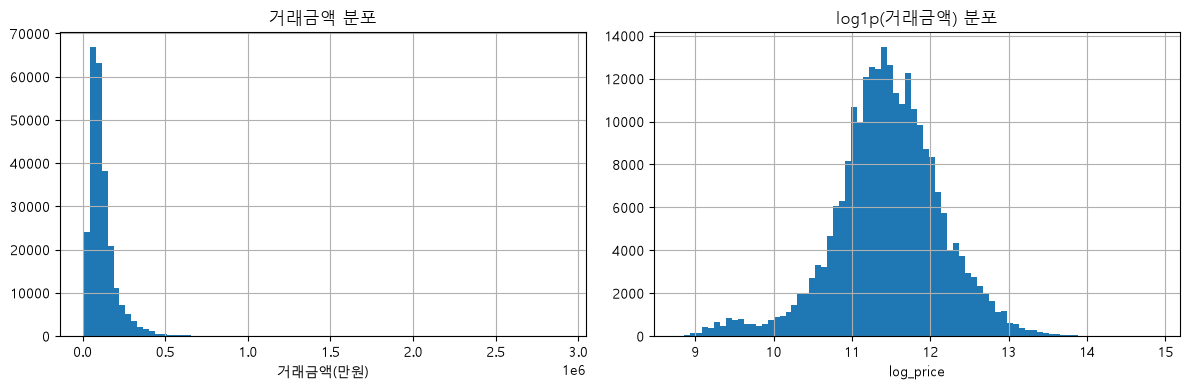

In [4]:
price_col = "거래금액"
df_eda = raw_df.copy()

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4)
)

df_eda[price_col].hist(
    bins=80,
    ax=axes[0]
)
axes[0].set_title("거래금액 분포")
axes[0].set_xlabel("거래금액(만원)")

np.log1p(
    df_eda[price_col]
).hist(
    bins=80,
    ax=axes[1]
)
axes[1].set_title("log1p(거래금액) 분포")
axes[1].set_xlabel("log_price")

plt.tight_layout()
plt.show()


In [5]:
display(
    df_eda[price_col].describe(
        percentiles=[
            0.01,
            0.25,
            0.5,
            0.75,
            0.9,
            0.95,
            0.99
        ]
    )
)

count         247385.0
mean     118397.583483
std       91037.261633
min             6500.0
1%             12000.0
25%            64700.0
50%            95000.0
75%           144500.0
90%           218000.0
95%           283000.0
99%           455000.0
max          2900000.0
Name: 거래금액, dtype: Float64

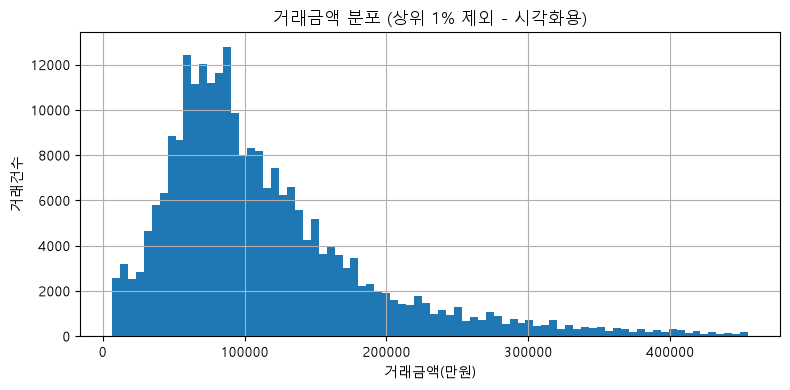

In [6]:
q99 = df_eda[price_col].quantile(0.99)

fig, ax = plt.subplots(
    figsize=(8, 4)
)

df_eda.loc[
    df_eda[price_col] <= q99,
    price_col
].hist(
    bins=80,
    ax=ax
)

ax.set_title(
    "거래금액 분포 "
    "(상위 1% 제외 - 시각화용)"
)

ax.set_xlabel("거래금액(만원)")
ax.set_ylabel("거래건수")

plt.tight_layout()
plt.show()

In [7]:
raw_df["log_price"] = np.log1p(
    raw_df["거래금액"]
)

오른쪽 꼬리가 긴 부동산 가격 분포는 로그변환 후 상대적으로 완화됩니다.

다만 5년 데이터에서는 연도별 가격 수준 자체가 바뀌므로,
이 분포만 보고 모델을 결정하지 않고 **시간순 검증 성능**을 최종 판단 기준으로 사용합니다.


## 2. 기본 + 시간 피처 엔지니어링

### 정적/기본 피처
- `연식` = 계약년도 - 건축년도
- `층_구분` = 저층 / 중층 / 고층
- `log_price` = log1p(거래금액) — **회귀 타겟/분석용**
- `평당가` — **현재 거래금액에서 직접 계산되므로 회귀 입력 금지**

### 5년용 시간 피처
- `거래년도`
- `거래월`
- `분기`
- `거래연월`
- `거래월일자`
- `경과월`
- `월_sin`, `월_cos` — 12개월 계절성 표현

`평당가`는 기존 하위 노트북 호환을 위해 이름을 유지하되,
이번 버전에서는 실제 **평(3.3058㎡)당 가격**으로 계산합니다.


In [208]:
df_fe = df_eda.copy()

before_merge_rows = len(df_fe)


# ============================================================
# 1. 날짜 / 시간 피처
# ============================================================

df_fe["거래년도"] = (
    df_fe["계약년도"]
    .astype("Int64")
)

df_fe["거래월"] = (
    df_fe["계약월"]
    .astype("Int64")
)

df_fe["분기"] = (
    ((df_fe["거래월"] - 1) // 3 + 1)
    .astype("Int64")
)

# 표시/그룹핑용 YYYYMM
df_fe["거래연월"] = (
    df_fe["거래년도"] * 100
    + df_fe["거래월"]
)


# 월 단위 실제 날짜
df_fe["거래월일자"] = pd.to_datetime(
    dict(
        year=df_fe["거래년도"],
        month=df_fe["거래월"],
        day=1,
    ),
    errors="coerce"
)


# ============================================================
# 2. 시간 경과 피처
# ============================================================

base_month = df_fe["거래월일자"].min()

df_fe["경과월"] = (
    (df_fe["거래월일자"].dt.year - base_month.year) * 12
    + (
        df_fe["거래월일자"].dt.month
        - base_month.month
    )
)


# 계절성 표현
df_fe["월_sin"] = np.sin(
    2 * np.pi * df_fe["거래월"] / 12
)

df_fe["월_cos"] = np.cos(
    2 * np.pi * df_fe["거래월"] / 12
)


# ============================================================
# 3. 기본 물리 피처
# ============================================================

df_fe["연식"] = (
    df_fe["거래년도"]
    - df_fe["건축년도"]
)

# 비정상 연식 제거
df_fe.loc[
    (df_fe["연식"] < 0)
    | (df_fe["연식"] > 100),
    "연식"
] = pd.NA


def floor_group(f):
    if pd.isna(f):
        return np.nan

    if f <= 5:
        return "저층"

    if f <= 15:
        return "중층"

    return "고층"


df_fe["층_구분"] = (
    df_fe["층"]
    .apply(floor_group)
)


# ============================================================
# 4. 타겟 / 분석 전용 피처
# ============================================================

# 회귀 입력 X로 사용 금지
df_fe["log_price"] = np.log1p(
    df_fe[price_col]
)


# 현재 거래가격 기반 → 회귀 입력 X로 사용 금지
valid_area = (
    df_fe["전용면적"].notna()
    & (df_fe["전용면적"] > 0)
)

df_fe["평당가"] = np.nan

df_fe.loc[
    valid_area,
    "평당가"
] = (
    df_fe.loc[valid_area, price_col]
    / (
        df_fe.loc[valid_area, "전용면적"]
        / 3.3058
    )
)
df_fe["log_평당가"] = np.log1p(
    df_fe["평당가"]
)

# ============================================================
# 5. 시군구 코드 정리
# ============================================================

df_fe["법정동시군구코드"] = (
    df_fe["법정동시군구코드"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

region_map = (
    sigungu_df[
        [
            "시군구코드",
            "시군구명",
            "시도명"
        ]
    ]
    .drop_duplicates("시군구코드")
    .copy()
)

region_map["시군구코드"] = (
    region_map["시군구코드"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)


# ============================================================
# 6. 지역 정보 매핑
# ============================================================

df_fe = df_fe.merge(
    region_map,
    left_on="법정동시군구코드",
    right_on="시군구코드",
    how="left",
    validate="many_to_one"
)


# ============================================================
# 7. 검증
# ============================================================

print("shape:", df_fe.shape)

print(
    "merge 전/후 행 수:",
    before_merge_rows,
    "→",
    len(df_fe)
)

print(
    "시군구명 결측치:",
    df_fe["시군구명"].isna().sum()
)

print(
    "연식 결측치:",
    df_fe["연식"].isna().sum()
)

print(
    "평당가 결측치:",
    df_fe["평당가"].isna().sum()
)

print(
    "거래 기간:",
    df_fe["거래월일자"].min(),
    "~",
    df_fe["거래월일자"].max()
)

print(
    "거래 월 수:",
    df_fe["거래월일자"]
    .dt.to_period("M")
    .nunique()
)
print(
    "log_평당가 결측치:",
    df_fe["log_평당가"].isna().sum()
)
display(
    df_fe[
        [
            "법정동시군구코드",
            "시군구명",
            "거래년도",
            "거래월",
            "분기",
            "경과월",
            "월_sin",
            "월_cos",
            "연식",
            "층_구분",
            "평당가",
            "log_평당가",
            "log_price",
        ]
    ].head()
)

shape: (247385, 49)
merge 전/후 행 수: 247385 → 247385
시군구명 결측치: 0
연식 결측치: 22
평당가 결측치: 0
거래 기간: 2021-07-01 00:00:00 ~ 2026-06-01 00:00:00
거래 월 수: 60
log_평당가 결측치: 0


,법정동시군구코드,시군구명,거래년도,거래월,분기,경과월,월_sin,월_cos,연식,층_구분,평당가,log_평당가,log_price
0,11110,종로구,2021,7,3,0,-0.5,-0.866025,21,중층,4027.954743,8.301262,11.849405
1,11110,종로구,2021,7,3,0,-0.5,-0.866025,13,중층,4827.006666,8.482189,11.835016
2,11110,종로구,2021,7,3,0,-0.5,-0.866025,4,저층,7384.075921,8.907216,12.149508
3,11110,종로구,2021,7,3,0,-0.5,-0.866025,21,중층,4026.516188,8.300905,11.849048
4,11110,종로구,2021,7,3,0,-0.5,-0.866025,17,중층,4503.515417,8.412836,12.23077


In [9]:
display(
    df_fe.loc[
        df_fe["연식"].isna(),
        [
            "단지명",
            "시군구명",
            "계약년도",
            "건축년도",
            "연식",
            "거래금액",
        ]
    ]
)

,단지명,시군구명,계약년도,건축년도,연식,거래금액
91259,은평서해그랑블,은평구,2021,2022,<NA>,50000
91409,DMCSKVIEW,은평구,2022,2023,<NA>,137000
94114,DMC파인시티자이,은평구,2024,2025,<NA>,95368
94641,DMC파인시티자이,은평구,2024,2025,<NA>,104000
95539,DMC아트포레자이,은평구,2024,2026,<NA>,112000
96807,센트레빌아스테리움시그니처,은평구,2025,2026,<NA>,77500
97137,센트레빌아스테리움시그니처,은평구,2025,2026,<NA>,77500
97363,DMC아트포레자이,은평구,2025,2026,<NA>,119900
97976,센트레빌아스테리움시그니처,은평구,2025,2026,<NA>,72900
98156,센트레빌아스테리움시그니처,은평구,2025,2026,<NA>,72900


In [10]:
# 월별 서울 전체 시장 흐름
monthly_market = (
    df_fe
    .groupby("거래월일자")
    .agg(
        중위거래가격=("거래금액", "median"),
        평균거래가격=("거래금액", "mean"),
        중위평당가=("평당가", "median"),
        거래량=("거래금액", "size"),
    )
    .reset_index()
)

display(monthly_market.head())
print("월 수:", len(monthly_market))

,거래월일자,중위거래가격,평균거래가격,중위평당가,거래량
0,2021-07-01,87000.0,104196.653333,4086.519896,4800
1,2021-08-01,91800.0,107454.859691,4268.937728,4205
2,2021-09-01,93000.0,112323.62799,4450.243118,2801
3,2021-10-01,89900.0,108490.876307,4308.546428,2296
4,2021-11-01,84650.0,107053.65097,4071.696896,1444


월 수: 60


기존 1년 버전과 달리 시간 피처가 추가됩니다.

`log_price`와 `평당가`는 **현재 거래금액을 직접 사용해 만든 값**이므로:
- 군집/EDA에서 가격 자체를 분석할 때는 사용 가능
- 회귀에서 `거래금액`을 예측하는 입력 피처로는 사용 금지

향후 회귀에 넣을 가격 맥락 피처는 아래의 **과거 월 lag 통계**를 사용합니다.


In [11]:
# ============================================================
# 연식 및 시간 피처 검증
# ============================================================

valid_age = df_fe["연식"].dropna()

print("[연식 분포]")
print(valid_age.describe())

print(
    "\n5년 이내 신축 비율:",
    round(
        (valid_age <= 5).mean(),
        3
    )
)

print(
    "연식 결측:",
    df_fe["연식"].isna().sum()
)


print("\n[시간 피처]")

display(
    df_fe[
        [
            "거래년도",
            "거래월",
            "분기",
            "경과월",
            "월_sin",
            "월_cos",
        ]
    ].describe()
)

print(
    "경과월 범위:",
    df_fe["경과월"].min(),
    "~",
    df_fe["경과월"].max()
)

[연식 분포]
count     247363.0
mean     20.977333
std      11.427632
min            0.0
25%           12.0
50%           22.0
75%           29.0
max           65.0
Name: 연식, dtype: Float64

5년 이내 신축 비율: 0.117
연식 결측: 22

[시간 피처]


,거래년도,거래월,분기,경과월,월_sin,월_cos
count,247385.0,247385.0,247385.0,247385.000000,247385.0,247385.0
mean,2024.217847,6.088692,2.352176,37.702852,0.060104,-0.182098
std,1.381703,3.056574,1.020836,15.931474,0.709766,0.677838
min,2021.0,1.0,1.0,0.000000,-1.0,-1.0
25%,2023.0,4.0,2.0,28.000000,-0.5,-0.866025
50%,2025.0,6.0,2.0,42.000000,0.0,-0.5
75%,2025.0,8.0,3.0,50.000000,0.866025,0.5
max,2026.0,12.0,4.0,59.000000,1.0,1.0


경과월 범위: 0 ~ 59


In [12]:
(df_fe["연식"] <= 5).mean()

np.float64(0.11749534085534215)

In [13]:
def age_group(age):
    if pd.isna(age):
        return pd.NA
    if age <= 5:
        return "신축"
    elif age <= 15:
        return "준신축"
    elif age <= 30:
        return "중년식"
    else:
        return "구축"

df_fe["연식_구분"] = (
    df_fe["연식"]
    .apply(age_group)
)

In [14]:
df_fe.columns

Index(['법정동시군구코드', '법정동읍면동코드', '법정동지번코드', '법정동본번코드', '법정동부번코드', '도로명',
       '도로명시군구코드', '도로명코드', '도로명일련번호코드', '도로명지상지하코드', '도로명건물본번호코드',
       '도로명건물부번호코드', '법정동', '단지명', '지번', '전용면적', '계약년도', '계약월', '계약일', '거래금액',
       '층', '건축년도', '단지일련번호', '해제여부', '해제사유발생일', '거래유형', '중개사소재지', '등기일자',
       '아파트동명', '매도자', '매수자', '토지임대부아파트여부', '거래연월', '계약일자', '거래년도', '거래월',
       '분기', '거래월일자', '경과월', '월_sin', '월_cos', '연식', '층_구분', 'log_price',
       '평당가', '시군구코드', '시군구명', '시도명', '연식_구분'],
      dtype='object')

연식 분포는 구별 주택 재고 구성과 거래량에 따라 크게 다를 수 있습니다.

5년 데이터에서는 특정 연도에 신축 입주가 집중되거나,
거래절벽 시기에 표본 구성이 달라질 수 있으므로 전체 평균만으로 시장 특성을 단정하지 않습니다.


## 3. 서울 수집 범위 검증

V2 수집 노트북은 처음부터 서울 25개 구만 호출합니다.

여기서는 전국 데이터에서 서울을 다시 자르는 단계가 아니라:
- 서울 외 데이터가 섞였는지
- 25개 구가 모두 존재하는지
- 월별/구별 누락이 있는지

를 검증합니다.


In [15]:
# ============================================================
# 서울 데이터 범위 검증
# ============================================================

seoul_names = set(
    sigungu_df["시군구명"]
)

non_seoul_mask = ~df_fe["시군구명"].isin(
    seoul_names
)

non_seoul_count = int(
    non_seoul_mask.sum()
)

print(
    "서울 외 데이터 건수:",
    non_seoul_count
)

if non_seoul_count > 0:
    raise ValueError(
        f"서울 외 데이터가 {non_seoul_count:,}건 존재합니다. "
        "수집 또는 지역 매핑 과정을 확인하세요."
    )


# ============================================================
# 최종 범위 확인
# ============================================================

print(
    "서울 구 수:",
    df_fe["시군구명"].nunique()
)

print(
    "거래 기간:",
    df_fe["거래월일자"].min(),
    "~",
    df_fe["거래월일자"].max()
)

print(
    "거래 월 수:",
    df_fe["거래월일자"]
    .dt.to_period("M")
    .nunique()
)

print(
    "최종 서울 shape:",
    df_fe.shape
)

서울 외 데이터 건수: 0
서울 구 수: 25
거래 기간: 2021-07-01 00:00:00 ~ 2026-06-01 00:00:00
거래 월 수: 60
최종 서울 shape: (247385, 49)


서울만 남긴 뒤에도 **60개월 전체가 존재하는지** 확인해야 합니다.

특정 구×월 조합의 거래가 실제로 0건일 수도 있지만,
많은 조합이 동시에 누락된다면 데이터 수집 실패 가능성을 먼저 점검합니다.


## 4. 5년 시간축 EDA

1년 데이터에서는 단순 월별 추이만 봐도 충분했지만,
5년 데이터에서는 **시장 상승/하락/회복 구간과 거래량 변화**를 함께 확인합니다.

먼저 연도별 거래량과 중위가격, 월별 거래량과 중위가격을 확인합니다.


,거래년도,거래건수,중위거래금액,평균거래금액,중위평당가,거래개월수,월평균거래건수
0,2021,16725,89000.0,107425.079342,4227.585978,6,2787.5
1,2022,12801,74000.0,97149.979455,3893.088643,12,1066.75
2,2023,35580,87000.0,106649.191175,4051.569850,12,2965.0
3,2024,57762,95900.0,119938.666926,4358.954556,12,4813.5
4,2025,83785,104900.0,127477.243994,4678.570586,12,6982.083333
5,2026,40732,93000.0,118980.861779,4254.667219,6,6788.666667


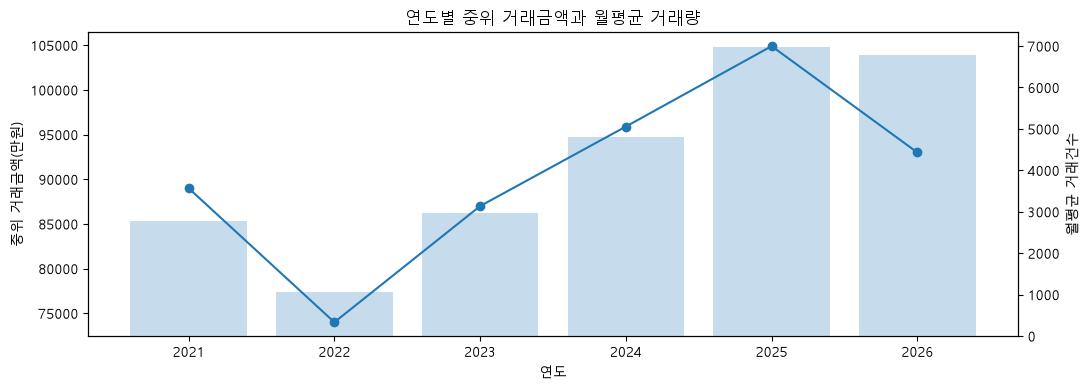

In [16]:
yearly_market = (
    df_fe
    .groupby("거래년도")
    .agg(
        거래건수=(price_col, "size"),
        중위거래금액=(price_col, "median"),
        평균거래금액=(price_col, "mean"),
        중위평당가=("평당가", "median"),
        거래개월수=("거래월", "nunique"),
    )
    .reset_index()
)

# 월평균 거래량
yearly_market["월평균거래건수"] = (
    yearly_market["거래건수"]
    / yearly_market["거래개월수"]
)

display(yearly_market)


# ============================================================
# 시각화
# ============================================================

fig, ax1 = plt.subplots(
    figsize=(11, 4)
)

# 중위 거래금액
ax1.plot(
    yearly_market["거래년도"],
    yearly_market["중위거래금액"],
    marker="o"
)

ax1.set_xlabel("연도")
ax1.set_ylabel("중위 거래금액(만원)")


# 월평균 거래량
ax2 = ax1.twinx()

ax2.bar(
    yearly_market["거래년도"],
    yearly_market["월평균거래건수"],
    alpha=0.25
)

ax2.set_ylabel("월평균 거래건수")


plt.title(
    "연도별 중위 거래금액과 월평균 거래량"
)

plt.tight_layout()
plt.show()

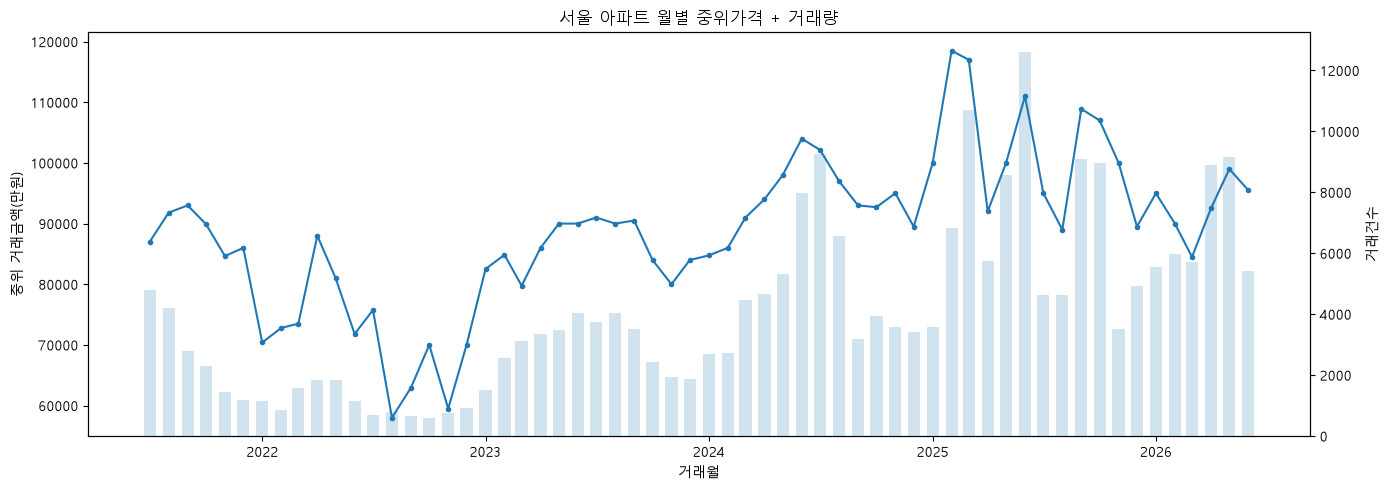

,거래월일자,거래건수,중위거래금액,평균거래금액
48,2025-07-01,4638,95000.0,129829.663433
49,2025-08-01,4614,89000.0,106113.396619
50,2025-09-01,9082,108900.0,121355.722198
51,2025-10-01,8950,107000.0,126877.152961
52,2025-11-01,3526,100000.0,131639.771412
53,2025-12-01,4936,89500.0,109582.931726
54,2026-01-01,5550,95000.0,118012.272432
55,2026-02-01,5983,90000.0,111782.154438
56,2026-03-01,5717,84500.0,105425.102151
57,2026-04-01,8905,92500.0,121814.692532


In [17]:
monthly_market = (
    df_fe.groupby("거래월일자")
    .agg(
        거래건수=(price_col, "size"),
        중위거래금액=(price_col, "median"),
        평균거래금액=(price_col, "mean"),
    )
    .reset_index()
    .sort_values("거래월일자")
)

fig, ax1 = plt.subplots(
    figsize=(14, 5)
)

ax1.plot(
    monthly_market["거래월일자"],
    monthly_market["중위거래금액"],
    marker="o",
    markersize=3
)
ax1.set_ylabel("중위 거래금액(만원)")
ax1.set_xlabel("거래월")

ax2 = ax1.twinx()
ax2.bar(
    monthly_market["거래월일자"],
    monthly_market["거래건수"],
    width=20,
    alpha=0.2
)
ax2.set_ylabel("거래건수")

plt.title("서울 아파트 월별 중위가격 + 거래량")
plt.tight_layout()
plt.show()

display(monthly_market.tail(12))


In [18]:
monthly_market["중위거래금액_3M"] = (
    monthly_market["중위거래금액"]
    .rolling(
        window=3,
        min_periods=1
    )
    .median()
)

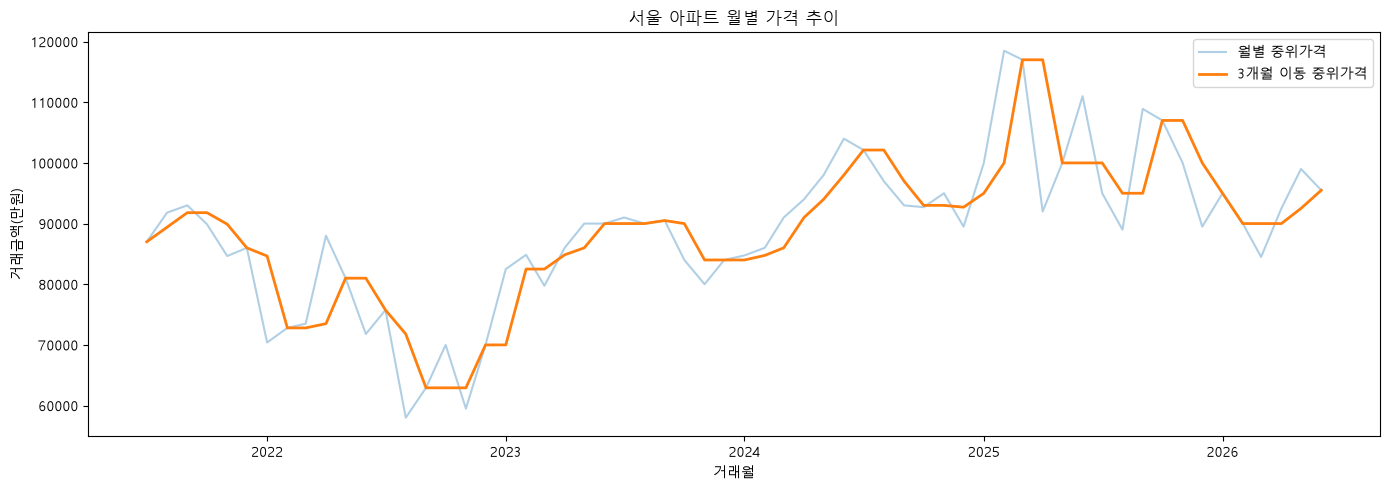

In [19]:
fig, ax = plt.subplots(
    figsize=(14, 5)
)

ax.plot(
    monthly_market["거래월일자"],
    monthly_market["중위거래금액"],
    alpha=0.35,
    label="월별 중위가격"
)

ax.plot(
    monthly_market["거래월일자"],
    monthly_market["중위거래금액_3M"],
    linewidth=2,
    label="3개월 이동 중위가격"
)

ax.set_xlabel("거래월")
ax.set_ylabel("거래금액(만원)")
ax.set_title("서울 아파트 월별 가격 추이")

ax.legend()

plt.tight_layout()
plt.show()

### 최근 월 신고 지연 체크

가장 최근 월 거래량이 직전 몇 달보다 지나치게 작으면 시장 급변이 아니라 **신고 미완결**일 수 있습니다.

이 경우 `01_data_collection_5year.ipynb`의 `REPORTING_LAG_MONTHS`를 2보다 더 크게 잡고 다시 수집하는 것이 안전합니다.


In [20]:
recent_counts = (
    monthly_market
    .set_index("거래월일자")["거래건수"]
    .tail(12)
)

display(recent_counts)

if len(recent_counts) >= 4:

    recent_month = recent_counts.index[-1]
    recent_count = recent_counts.iloc[-1]

    prev_3months = recent_counts.iloc[-4:-1]
    prev_median = prev_3months.median()

    ratio = (
        recent_count / prev_median
        if prev_median > 0
        else np.nan
    )

    print(
        "\n최근월:",
        recent_month.strftime("%Y-%m")
    )

    print(
        "최근월 거래건수:",
        f"{recent_count:,}"
    )

    print(
        "직전 3개월 거래건수 중앙값:",
        f"{prev_median:,.0f}"
    )

    print(
        "최근월 / 직전3개월 중앙값 비율:",
        round(ratio, 3)
    )

    if ratio < 0.6:
        print(
            "⚠ 최근월 거래량이 직전 3개월 대비 많이 낮습니다."
        )
        print(
            "신고 지연 또는 실제 거래량 급감 여부를 확인하세요."
        )
    else:
        print(
            "✅ 최근월 거래량은 크게 비정상적이지 않습니다."
        )

거래월일자
2025-07-01    4638
2025-08-01    4614
2025-09-01    9082
2025-10-01    8950
2025-11-01    3526
2025-12-01    4936
2026-01-01    5550
2026-02-01    5983
2026-03-01    5717
2026-04-01    8905
2026-05-01    9174
2026-06-01    5403
Name: 거래건수, dtype: Int64


최근월: 2026-06
최근월 거래건수: 5,403
직전 3개월 거래건수 중앙값: 8,905
최근월 / 직전3개월 중앙값 비율: 0.607
✅ 최근월 거래량은 크게 비정상적이지 않습니다.


## 5. 누수 없는 과거 월 기반 시장 피처

현재 거래의 가격을 이용한 `지역평균가`, `평당가`, 현재월 지역 통계는 회귀 입력으로 쓰면 누수가 발생할 수 있습니다.

따라서 각 거래월 **이전 월까지의 정보만** 사용한 지역별 시계열 피처를 만듭니다.

생성 예:
- `구_전월_중위가격`
- `구_과거3개월_중위가격`
- `구_과거6개월_중위가격`
- `구_전월_거래량`
- `구_과거3개월_거래량`
- `구_전월_가격변화율`
- `서울_전월_중위가격`

첫 몇 달은 과거 이력이 부족하므로 NaN이 자연스럽게 발생하며,
최종 회귀에서 Train 기준 fallback/imputation을 적용합니다.

> 이 피처들은 월별로 순차 갱신되는 서비스 시나리오를 가정한 causal lag입니다.
> 최종 고정 holdout 평가 정책은 `04_regression`에서 명시적으로 다시 고정합니다.


In [21]:
# ============================================================
# 과거 시장 Lag Feature 생성
# ============================================================

# 셀 재실행 시 기존 lag 컬럼 중복 방지
old_lag_cols = [
    "구_전월_중위가격",
    "구_전월_중위평당가",
    "구_전월_거래량",
    "구_과거3개월_중위가격",
    "구_과거6개월_중위가격",
    "구_과거3개월_거래량",
    "구_과거6개월_거래량",
    "구_전월_가격변화율",
    "서울_전월_중위가격",
    "서울_과거3개월_중위가격",
    "서울_과거6개월_중위가격",
    "서울_전월_거래량",
    "서울_과거3개월_거래량",
    "서울_전월_가격변화율",
]

df_fe = df_fe.drop(
    columns=[
        col for col in old_lag_cols
        if col in df_fe.columns
    ],
    errors="ignore"
)


# ------------------------------------------------------------
# 1. 구 × 월 원 통계
# 현재월 통계 자체는 분석용
# 회귀에는 아래에서 shift한 값만 사용
# ------------------------------------------------------------

monthly_region_stats = (
    df_fe
    .groupby(
        [
            "법정동시군구코드",
            "시군구명",
            "거래월일자",
        ]
    )
    .agg(
        월중위거래금액=(price_col, "median"),
        월평균거래금액=(price_col, "mean"),
        월중위평당가=("평당가", "median"),
        월거래량=(price_col, "size"),
    )
    .reset_index()
    .sort_values(
        [
            "법정동시군구코드",
            "거래월일자",
        ]
    )
)


region_group = monthly_region_stats.groupby(
    "법정동시군구코드",
    group_keys=False
)


# ------------------------------------------------------------
# 2. 구 단위 과거 시장 피처
# t월 예측 → t-1 이전 데이터만 사용
# ------------------------------------------------------------

monthly_region_stats["구_전월_중위가격"] = (
    region_group["월중위거래금액"]
    .shift(1)
)

monthly_region_stats["구_전월_중위평당가"] = (
    region_group["월중위평당가"]
    .shift(1)
)

monthly_region_stats["구_전월_거래량"] = (
    region_group["월거래량"]
    .shift(1)
)


# 과거 3개월
monthly_region_stats["구_과거3개월_중위가격"] = (
    region_group["월중위거래금액"]
    .transform(
        lambda s:
            s.shift(1)
            .rolling(
                window=3,
                min_periods=3
            )
            .median()
    )
)

monthly_region_stats["구_과거3개월_거래량"] = (
    region_group["월거래량"]
    .transform(
        lambda s:
            s.shift(1)
            .rolling(
                window=3,
                min_periods=3
            )
            .sum()
    )
)


# 과거 6개월
monthly_region_stats["구_과거6개월_중위가격"] = (
    region_group["월중위거래금액"]
    .transform(
        lambda s:
            s.shift(1)
            .rolling(
                window=6,
                min_periods=6
            )
            .median()
    )
)

monthly_region_stats["구_과거6개월_거래량"] = (
    region_group["월거래량"]
    .transform(
        lambda s:
            s.shift(1)
            .rolling(
                window=6,
                min_periods=6
            )
            .sum()
    )
)


# t월에서 사용 가능한 가장 최근 가격 변화
# (t-1 가격 / t-2 가격) - 1
monthly_region_stats["구_전월_가격변화율"] = (
    region_group["월중위거래금액"]
    .transform(
        lambda s:
            s.shift(1) / s.shift(2) - 1
    )
)


# ------------------------------------------------------------
# 3. 서울 전체 월별 시장
# ------------------------------------------------------------

seoul_monthly_stats = (
    df_fe
    .groupby("거래월일자")
    .agg(
        서울_월중위가격=(price_col, "median"),
        서울_월거래량=(price_col, "size"),
    )
    .reset_index()
    .sort_values("거래월일자")
)


# 전월
seoul_monthly_stats["서울_전월_중위가격"] = (
    seoul_monthly_stats["서울_월중위가격"]
    .shift(1)
)

seoul_monthly_stats["서울_전월_거래량"] = (
    seoul_monthly_stats["서울_월거래량"]
    .shift(1)
)


# 과거 3개월
seoul_monthly_stats["서울_과거3개월_중위가격"] = (
    seoul_monthly_stats["서울_월중위가격"]
    .shift(1)
    .rolling(
        window=3,
        min_periods=3
    )
    .median()
)

seoul_monthly_stats["서울_과거3개월_거래량"] = (
    seoul_monthly_stats["서울_월거래량"]
    .shift(1)
    .rolling(
        window=3,
        min_periods=3
    )
    .sum()
)


# 과거 6개월
seoul_monthly_stats["서울_과거6개월_중위가격"] = (
    seoul_monthly_stats["서울_월중위가격"]
    .shift(1)
    .rolling(
        window=6,
        min_periods=6
    )
    .median()
)


# 가격 변화율
seoul_monthly_stats["서울_전월_가격변화율"] = (
    seoul_monthly_stats["서울_월중위가격"]
    .shift(1)
    / seoul_monthly_stats["서울_월중위가격"]
    .shift(2)
    - 1
)


# ------------------------------------------------------------
# 4. Merge
# ------------------------------------------------------------

lag_region_cols = [
    "구_전월_중위가격",
    "구_전월_중위평당가",
    "구_전월_거래량",
    "구_과거3개월_중위가격",
    "구_과거6개월_중위가격",
    "구_과거3개월_거래량",
    "구_과거6개월_거래량",
    "구_전월_가격변화율",
]

seoul_lag_cols = [
    "서울_전월_중위가격",
    "서울_과거3개월_중위가격",
    "서울_과거6개월_중위가격",
    "서울_전월_거래량",
    "서울_과거3개월_거래량",
    "서울_전월_가격변화율",
]


before_rows = len(df_fe)

df_fe = df_fe.merge(
    monthly_region_stats[
        [
            "법정동시군구코드",
            "거래월일자",
        ]
        + lag_region_cols
    ],
    on=[
        "법정동시군구코드",
        "거래월일자",
    ],
    how="left",
    validate="many_to_one",
)

df_fe = df_fe.merge(
    seoul_monthly_stats[
        ["거래월일자"]
        + seoul_lag_cols
    ],
    on="거래월일자",
    how="left",
    validate="many_to_one",
)


# ------------------------------------------------------------
# 5. 검증
# ------------------------------------------------------------

print("[과거 시장 피처 생성 완료]")

print(
    "merge 전/후:",
    before_rows,
    "→",
    len(df_fe)
)

print(
    "지역×월 행 수:",
    len(monthly_region_stats)
)

print(
    "지역 수:",
    monthly_region_stats[
        "법정동시군구코드"
    ].nunique()
)

print(
    "월 수:",
    monthly_region_stats[
        "거래월일자"
    ].nunique()
)


lag_cols = (
    lag_region_cols
    + seoul_lag_cols
)

display(
    df_fe[
        [
            "시군구명",
            "거래월일자",
        ]
        + lag_cols
    ].head(20)
)

print("\n[lag 피처 결측 비율]")

display(
    df_fe[lag_cols]
    .isna()
    .mean()
    .sort_values(ascending=False)
    .to_frame("결측비율")
)

[과거 시장 피처 생성 완료]
merge 전/후: 247385 → 247385
지역×월 행 수: 1500
지역 수: 25
월 수: 60


,시군구명,거래월일자,구_전월_중위가격,구_전월_중위평당가,구_전월_거래량,구_과거3개월_중위가격,구_과거6개월_중위가격,구_과거3개월_거래량,구_과거6개월_거래량,구_전월_가격변화율,서울_전월_중위가격,서울_과거3개월_중위가격,서울_과거6개월_중위가격,서울_전월_거래량,서울_과거3개월_거래량,서울_전월_가격변화율
0,종로구,2021-07-01,<NA>,NaN,<NA>,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN,NaN,<NA>,NaN,<NA>
1,종로구,2021-07-01,<NA>,NaN,<NA>,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN,NaN,<NA>,NaN,<NA>
2,종로구,2021-07-01,<NA>,NaN,<NA>,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN,NaN,<NA>,NaN,<NA>
3,종로구,2021-07-01,<NA>,NaN,<NA>,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN,NaN,<NA>,NaN,<NA>
4,종로구,2021-07-01,<NA>,NaN,<NA>,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN,NaN,<NA>,NaN,<NA>
5,종로구,2021-07-01,<NA>,NaN,<NA>,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN,NaN,<NA>,NaN,<NA>
6,종로구,2021-07-01,<NA>,NaN,<NA>,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN,NaN,<NA>,NaN,<NA>
7,종로구,2021-07-01,<NA>,NaN,<NA>,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN,NaN,<NA>,NaN,<NA>
8,종로구,2021-07-01,<NA>,NaN,<NA>,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN,NaN,<NA>,NaN,<NA>
9,종로구,2021-07-01,<NA>,NaN,<NA>,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN,NaN,<NA>,NaN,<NA>



[lag 피처 결측 비율]


,결측비율
구_과거6개월_중위가격,0.067607
구_과거6개월_거래량,0.067607
서울_과거6개월_중위가격,0.067607
서울_과거3개월_거래량,0.047723
구_과거3개월_거래량,0.047723
구_과거3개월_중위가격,0.047723
서울_과거3개월_중위가격,0.047723
서울_전월_가격변화율,0.036401
구_전월_가격변화율,0.036401
구_전월_중위가격,0.019403


In [22]:
reg_df = (
    df_fe[
        df_fe["거래월일자"]
        >= pd.Timestamp("2022-01-01")
    ]
    .copy()
)

print(
    "회귀 데이터 기간:",
    reg_df["거래월일자"].min(),
    "~",
    reg_df["거래월일자"].max()
)

print(
    "회귀 데이터 shape:",
    reg_df.shape
)

회귀 데이터 기간: 2022-01-01 00:00:00 ~ 2026-06-01 00:00:00
회귀 데이터 shape: (230660, 63)


In [23]:
lag_cols = (
    lag_region_cols
    + seoul_lag_cols
)

display(
    reg_df[lag_cols]
    .isna()
    .sum()
    .to_frame("결측건수")
)

,결측건수
구_전월_중위가격,0
구_전월_중위평당가,0
구_전월_거래량,0
구_과거3개월_중위가격,0
구_과거6개월_중위가격,0
구_과거3개월_거래량,0
구_과거6개월_거래량,0
구_전월_가격변화율,0
서울_전월_중위가격,0
서울_과거3개월_중위가격,0


### 시장 국면 군집용 월별 테이블

`market_monthly_5y.parquet`에는 **지역×월 실제 집계값과 lag 피처**를 함께 저장합니다.

향후 `03_clustering`에서 거래행 자체가 아니라 `지역×월`을 한 관측치로 두고:
- 가격 변화율
- 거래량 변화
- 가격 변동성

등을 이용해 `상승 활황 / 침체 / 회복 초기` 같은 **시장 국면 군집**을 실험할 수 있습니다.

현재월 실제 통계는 시장 국면을 사후 분석하는 데 사용할 수 있지만,
미래 가격 회귀 입력으로 넣을 때는 lag 컬럼만 사용합니다.


## 6. 아파트 좌표 지오코딩 (카카오 API)

같은 단지는 5년 동안 여러 번 거래되므로,
`시군구명 + 법정동 + 지번 + 단지명`의 고유 주소 기준으로 캐싱해서 API 호출을 최소화합니다.

5년으로 거래행이 늘어나도 **고유 단지/주소 수는 거래건수만큼 증가하지 않으므로**
기존 `geocode_cache.csv`를 적극 재사용할 수 있습니다.


In [24]:
KAKAO_API_KEY = os.environ.get(
    "KAKAO_REST_API_KEY",
    ""
)

if not KAKAO_API_KEY:
    raise ValueError(
        "KAKAO_REST_API_KEY 환경변수가 설정되지 않았습니다."
    )


def geocode_address(query: str):
    url = (
        "https://dapi.kakao.com/"
        "v2/local/search/address.json"
    )

    headers = {
        "Authorization": f"KakaoAK {KAKAO_API_KEY}"
    }

    params = {
        "query": query
    }

    try:
        resp = requests.get(
            url,
            headers=headers,
            params=params,
            timeout=5
        )

        resp.raise_for_status()

        docs = resp.json().get(
            "documents",
            []
        )

        if not docs:
            print(
                f"⚠ 검색 결과 없음: {query}"
            )
            return None, None

        lat = float(docs[0]["y"])
        lon = float(docs[0]["x"])

        return lat, lon

    except requests.RequestException as e:
        print(
            f"❌ API 요청 실패: {query}"
        )
        print(e)

        return None, None


# 테스트
lat, lon = geocode_address(
    "서울특별시 종로구 숭인동"
)

print(
    "위도:",
    lat,
    "경도:",
    lon
)

위도: 37.5745280159936 경도: 127.019597569646


테스트 쿼리 "서울특별시 종로구 숭인동"이 위도 37.57 / 경도 127.02로 정상 반환되어, 카카오 지오코딩 API 연동이 정상 작동함을 확인했습니다.

In [25]:
# ============================================================
# 지오코딩용 주소 생성
# ============================================================

# 문자열 정리
for col in ["시군구명", "법정동", "지번", "단지명"]:
    df_fe[col] = (
        df_fe[col]
        .astype("string")
        .str.strip()
    )


# ------------------------------------------------------------
# 캐싱 / 단지 식별용 주소
# ------------------------------------------------------------

df_fe["주소"] = (
    "서울특별시 "
    + df_fe["시군구명"].fillna("")
    + " "
    + df_fe["법정동"].fillna("")
    + " "
    + df_fe["지번"].fillna("")
    + " "
    + df_fe["단지명"].fillna("")
).str.replace(
    r"\s+",
    " ",
    regex=True
).str.strip()


# ------------------------------------------------------------
# Kakao 지오코딩 검색용
# 단지명은 제외하고 지번 주소 중심으로 검색
# ------------------------------------------------------------

df_fe["검색주소"] = (
    "서울특별시 "
    + df_fe["시군구명"].fillna("")
    + " "
    + df_fe["법정동"].fillna("")
    + " "
    + df_fe["지번"].fillna("")
).str.replace(
    r"\s+",
    " ",
    regex=True
).str.strip()


# ------------------------------------------------------------
# 실제 API 호출 대상
# 검색주소 기준 중복 제거
# ------------------------------------------------------------

unique_address_df = (
    df_fe[
        [
            "검색주소",
        ]
    ]
    .dropna()
    .drop_duplicates()
    .reset_index(drop=True)
)

print(
    f"고유 검색주소 수: {len(unique_address_df):,}"
)

print(
    f"전체 거래 건수: {len(df_fe):,}"
)

display(
    unique_address_df.head()
)

고유 검색주소 수: 7,834
전체 거래 건수: 247,385


,검색주소
0,서울특별시 종로구 무악동 82
1,서울특별시 종로구 사직동 9
2,서울특별시 종로구 홍파동 199
3,서울특별시 종로구 내수동 73
4,서울특별시 종로구 창신동 703


실행 결과에서 **고유 주소 수 / 전체 거래건수 / 기존 캐시 재사용 수**를 확인합니다.

5년 데이터는 거래행이 크게 늘지만 동일 단지의 반복 거래가 많기 때문에,
실제 신규 지오코딩 API 호출 수는 거래행 증가폭보다 훨씬 작을 가능성이 큽니다.


In [26]:
# ============================================================
# 지오코딩 캐시 준비
# ============================================================

GEOCODE_CACHE_PATH = EXTERNAL_DIR / "geocode_cache.csv"
GEOCODE_COLUMNS = ["검색주소", "위도", "경도"]


def load_geocode_cache(path):
    """저장된 지오코딩 결과를 불러온다."""
    if not path.exists():
        return pd.DataFrame(columns=GEOCODE_COLUMNS)

    cache = pd.read_csv(
        path,
        encoding="utf-8-sig"
    )

    return (
        cache[GEOCODE_COLUMNS]
        .drop_duplicates("검색주소", keep="last")
        .reset_index(drop=True)
    )


geo_cache = load_geocode_cache(
    GEOCODE_CACHE_PATH
)

In [27]:
# ============================================================
# 지오코딩 대상 확인
# ============================================================

completed_addresses = set(
    geo_cache
    .dropna(subset=["위도", "경도"])
    ["검색주소"]
)

todo = (
    unique_address_df.loc[
        ~unique_address_df["검색주소"].isin(completed_addresses),
        "검색주소"
    ]
    .tolist()
)

print(f"전체 주소 : {len(unique_address_df):,}")
print(f"처리 완료 : {len(completed_addresses):,}")
print(f"처리 예정 : {len(todo):,}")

전체 주소 : 7,834
처리 완료 : 7,834
처리 예정 : 0


In [28]:
# ============================================================
# 지오코딩 샘플 테스트
# ============================================================

test_addresses = todo[:3]

for address in test_addresses:
    lat, lon = geocode_address(address)

    print(
        f"{address}"
        f"\n→ 위도: {lat}, 경도: {lon}\n"
    )

In [29]:
# ============================================================
# 지오코딩 수집 함수
# ============================================================

def collect_geocoding(
    addresses,
    cache_df,
    save_path,
    save_every=50,
    sleep_time=0.05
):
    results = []

    for i, address in enumerate(addresses, 1):
        lat, lon = geocode_address(address)

        results.append({
            "검색주소": address,
            "위도": lat,
            "경도": lon,
        })

        time.sleep(sleep_time)

        if i % save_every == 0 or i == len(addresses):
            new_data = pd.DataFrame(results)

            cache_df = (
                pd.concat(
                    [cache_df, new_data],
                    ignore_index=True
                )
                .drop_duplicates(
                    "검색주소",
                    keep="last"
                )
                .reset_index(drop=True)
            )

            cache_df.to_csv(
                save_path,
                index=False,
                encoding="utf-8-sig"
            )

            results = []

            print(
                f"진행: {i:,}/{len(addresses):,}"
            )

    return cache_df

In [30]:
# ============================================================
# 전체 지오코딩 실행
# ============================================================

geo_cache = collect_geocoding(
    addresses=todo,
    cache_df=geo_cache,
    save_path=GEOCODE_CACHE_PATH,
    save_every=50
)

실행 결과에서 **고유 주소 수 / 전체 거래건수 / 기존 캐시 재사용 수**를 확인합니다.

5년 데이터는 거래행이 크게 늘지만 동일 단지의 반복 거래가 많기 때문에,
실제 신규 지오코딩 API 호출 수는 거래행 증가폭보다 훨씬 작을 가능성이 큽니다.


In [31]:
# ============================================================
# 지오코딩 결과 확인
# ============================================================

total_count = len(geo_cache)

success_mask = (
    geo_cache["위도"].notna()
    & geo_cache["경도"].notna()
)

success_count = success_mask.sum()
fail_count = total_count - success_count

success_rate = (
    success_count / total_count
    if total_count > 0
    else 0
)

print(f"전체 주소 : {total_count:,}")
print(f"성공      : {success_count:,}")
print(f"실패      : {fail_count:,}")
print(f"성공률    : {success_rate:.1%}")

전체 주소 : 7,834
성공      : 7,834
실패      : 0
성공률    : 100.0%


In [32]:
# ============================================================
# 실패 주소 확인
# ============================================================

failed_geo = (
    geo_cache.loc[
        ~success_mask,
        ["검색주소"]
    ]
    .reset_index(drop=True)
)

print(f"실패 주소 수 : {len(failed_geo):,}")

display(
    failed_geo.head(20)
)

실패 주소 수 : 0


,검색주소


In [33]:
# ============================================================
# 실패 주소 원본 정보 확인
# ============================================================

failed_detail = (
    df_fe.loc[
        df_fe["검색주소"].isin(
            failed_geo["검색주소"]
        ),
        [
            "시군구명",
            "법정동",
            "지번",
            "단지명",
            "검색주소",
        ]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

display(failed_detail)

,시군구명,법정동,지번,단지명,검색주소


In [34]:
# ============================================================
# 지오코딩 실패 영향 확인
# ============================================================

failed_mask = df_fe["검색주소"].isin(
    failed_geo["검색주소"]
)

failed_trade_count = failed_mask.sum()
failed_trade_rate = failed_trade_count / len(df_fe)

print(f"실패 주소 수   : {len(failed_geo):,}")
print(f"영향 거래 건수 : {failed_trade_count:,}")
print(f"영향 거래 비율 : {failed_trade_rate:.3%}")

실패 주소 수   : 0
영향 거래 건수 : 0
영향 거래 비율 : 0.000%


In [35]:
# ============================================================
# 실패 주소 원본 정보 확인
# ============================================================

road_cols = [
    "시군구명",
    "법정동",
    "지번",
    "단지명",
    "도로명",
    "도로명시군구코드",
    "도로명건물본번호코드",
    "도로명건물부번호코드",
    "검색주소",
]

available_cols = [
    col for col in road_cols
    if col in df_fe.columns
]

failed_detail = (
    df_fe.loc[
        failed_mask,
        available_cols
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

display(failed_detail)

,시군구명,법정동,지번,단지명,도로명,도로명시군구코드,도로명건물본번호코드,도로명건물부번호코드,검색주소


In [36]:
def format_building_number(main_no, sub_no):
    if pd.isna(main_no):
        return ""

    main_no = str(int(float(main_no)))

    if pd.isna(sub_no) or float(sub_no) == 0:
        return main_no

    return f"{main_no}-{int(float(sub_no))}"

In [37]:
# ============================================================
# 도로명 fallback 주소 생성
# ============================================================

failed_detail["건물번호"] = failed_detail.apply(
    lambda row: format_building_number(
        row.get("도로명건물본번호코드"),
        row.get("도로명건물부번호코드")
    ),
    axis=1
)

failed_detail["도로명검색주소"] = (
    "서울특별시 "
    + failed_detail["도로명"].fillna("")
    + " "
    + failed_detail["건물번호"].fillna("")
).str.replace(
    r"\s+",
    " ",
    regex=True
).str.strip()

display(
    failed_detail[
        [
            "검색주소",
            "단지명",
            "도로명검색주소",
        ]
    ]
)

,검색주소,단지명,도로명검색주소


In [38]:
# ============================================================
# 도로명 주소로 2차 지오코딩
# ============================================================

fallback_results = []

for _, row in failed_detail.iterrows():
    lat, lon = geocode_address(
        row["도로명검색주소"]
    )

    fallback_results.append({
        "검색주소": row["검색주소"],
        "도로명검색주소": row["도로명검색주소"],
        "위도": lat,
        "경도": lon,
    })

fallback_geo = pd.DataFrame(
    fallback_results
)

display(fallback_geo)

""


In [39]:
# ============================================================
# 2차 검색 결과 반영
# ============================================================

fallback_success = (
    fallback_geo
    .dropna(subset=["위도", "경도"])
    .set_index("검색주소")
)

geo_cache = geo_cache.set_index("검색주소")

geo_cache.update(
    fallback_success[
        ["위도", "경도"]
    ]
)

geo_cache = geo_cache.reset_index()

geo_cache.to_csv(
    GEOCODE_CACHE_PATH,
    index=False,
    encoding="utf-8-sig"
)

KeyError: ['위도', '경도']

In [40]:
success_mask = (
    geo_cache["위도"].notna()
    & geo_cache["경도"].notna()
)

print(
    "최종 실패 주소 수:",
    (~success_mask).sum()
)

최종 실패 주소 수: 0


In [41]:
# ============================================================
# 지오코딩 결과 병합
# ============================================================

before_rows = len(df_fe)

df_fe = df_fe.merge(
    geo_cache[
        [
            "검색주소",
            "위도",
            "경도",
        ]
    ],
    on="검색주소",
    how="left",
    validate="many_to_one"
)

print(
    "merge 전/후:",
    before_rows,
    "→",
    len(df_fe)
)

merge 전/후: 247385 → 247385


In [42]:
# ============================================================
# 좌표 병합 결과 확인
# ============================================================

coord_missing = (
    df_fe[
        [
            "위도",
            "경도",
        ]
    ]
    .isna()
    .any(axis=1)
    .sum()
)

print(f"전체 거래 건수 : {len(df_fe):,}")
print(f"좌표 결측 건수 : {coord_missing:,}")

display(
    df_fe[
        [
            "단지명",
            "검색주소",
            "위도",
            "경도",
        ]
    ].head()
)

전체 거래 건수 : 247,385
좌표 결측 건수 : 0


,단지명,검색주소,위도,경도
0,현대,서울특별시 종로구 무악동 82,37.575631,126.961060
1,광화문스페이스본(101동~105동),서울특별시 종로구 사직동 9,37.574417,126.968881
2,경희궁자이(2단지),서울특별시 종로구 홍파동 199,37.570696,126.963609
3,현대,서울특별시 종로구 무악동 82,37.575631,126.961060
4,경희궁의아침4단지,서울특별시 종로구 내수동 73,37.572614,126.972273


In [43]:
# ============================================================
# 좌표 범위 검증
# ============================================================

coord_check = df_fe[
    ["위도", "경도"]
].describe()

display(coord_check)

invalid_coord = ~(
    df_fe["위도"].between(37.4, 37.8)
    & df_fe["경도"].between(126.7, 127.3)
)

print(
    f"서울 범위 밖 좌표 : {invalid_coord.sum():,}"
)

,위도,경도
count,247385.000000,247385.000000
mean,37.552018,126.996791
std,0.053074,0.090551
min,37.434446,126.806100
25%,37.506547,126.919331
50%,37.548594,127.016217
75%,37.589498,127.066174
max,37.687633,127.180765


서울 범위 밖 좌표 : 0


실행 후 좌표 매핑 성공률과 실패 주소 수를 확인합니다.

5년 확장으로 과거 단지까지 포함되면서 실패 주소가 늘 수 있으므로,
실패가 특정 단지/옛 지번에 집중되는지 별도로 확인합니다.


## 7. 최근접 지하철역 거리

아파트와 지하철역의 위도·경도를 기반으로
`sklearn.neighbors.BallTree`의 `haversine` 거리를 사용하여
각 아파트에서 가장 가까운 지하철역을 탐색합니다.

최근접 역까지의 거리는 지구 반지름을 곱해 미터(m) 단위의
`역세권거리_m` 피처로 생성합니다.

추가로 최근접 역의 이름과 노선 정보를 저장하여
입지 분석 및 웹 서비스 설명에 활용합니다.

### 5년 데이터에서의 시간적 주의사항

현재 `subway_stations.xlsx`가 **현재 시점의 역 목록**이라면,
5년 데이터 기간 중 새로 개통한 역이 과거 거래 시점에도
존재했던 것처럼 계산될 수 있습니다.

따라서 현재 버전의 `역세권거리_m`은
**현재 기준 입지 proxy**로 사용합니다.

향후 역 개통일 데이터가 확보되면
거래 시점에 실제 운영 중이었던 역만 후보에 포함하여

`거래일자 >= 역 개통일`

조건을 적용한 시점별 최근접 거리로 고도화할 수 있습니다.

In [44]:
subway_df = pd.read_excel(EXTERNAL_DIR / "subway_stations.xlsx")
print(subway_df.shape)
subway_df[["역사명", "노선명", "역위도", "역경도", "운영기관명"]].head()


(1099, 15)


,역사명,노선명,역위도,역경도,운영기관명
0,신사,신분당선,37.516125,127.019761,경기도 신분당선
1,논현,신분당선,37.511115,127.021366,경기도 신분당선
2,신논현,신분당선,37.504555,127.024531,경기도 신분당선
3,강남,신분당선,37.497385,127.027879,경기도 신분당선
4,양재(서초구청),신분당선,37.484454,127.034099,경기도 신분당선


지하철역 데이터는 1,099개 역(수도권 전체 노선 포함으로 보임) 기준이며, 위경도 좌표가 포함되어 있어 바로 `nearest_facility` 함수에 사용할 수 있습니다.

In [45]:
from sklearn.neighbors import BallTree

EARTH_RADIUS_M = 6_371_000

apartment_coords = np.radians(
    df_fe[["위도", "경도"]].to_numpy()
)

subway_coords = np.radians(
    subway_df[["역위도", "역경도"]].to_numpy()
)

subway_tree = BallTree(
    subway_coords,
    metric="haversine"
)

distances, indices = subway_tree.query(
    apartment_coords,
    k=1
)

nearest_idx = indices[:, 0]

df_fe["역세권거리_m"] = (
    distances[:, 0] * EARTH_RADIUS_M
)

df_fe["최근접역"] = (
    subway_df.iloc[nearest_idx]["역사명"]
    .to_numpy()
)

df_fe["최근접노선"] = (
    subway_df.iloc[nearest_idx]["노선명"]
    .to_numpy()
)

역세권거리는 중앙값 약 499m, 평균 약 760m로 우측 꼬리가 긴 분포입니다(최댓값 약 9,328m). 대부분의 서울 아파트가 도보권(500m 내외)에 지하철역을 두고 있다는 점과 부합합니다.

In [46]:
# ============================================================
# 지하철 거리 이상치 확인
# ============================================================

farthest_apartments = (
    df_fe[
        [
            "법정동",
            "단지명",
            "최근접역",
            "역세권거리_m",
        ]
    ]
    .sort_values(
        "역세권거리_m",
        ascending=False
    )
    .head(5)
)

display(farthest_apartments)


# ============================================================
# 지하철 거리 분포 확인
# ============================================================

print(
    df_fe["역세권거리_m"].describe(
        percentiles=[
            0.5,
            0.75,
            0.9,
            0.95,
            0.99,
        ]
    )
)

,법정동,단지명,최근접역,역세권거리_m
524,평창동,일성빌라트,북한산보국문,3143.458506
1497,평창동,일성빌라트,북한산보국문,3143.458506
1330,평창동,일성빌라트,북한산보국문,3143.458506
550,평창동,일성빌라트,북한산보국문,3143.458506
404,평창동,일성빌라트,북한산보국문,3143.458506


count    247385.000000
mean        531.556983
std         321.404771
min          24.436073
50%         461.863773
75%         659.006539
90%         928.849431
95%        1165.589645
99%        1714.925153
max        3143.458506
Name: 역세권거리_m, dtype: float64


In [47]:
# ============================================================
# 역세권 거리 구간
# ============================================================

def classify_subway_distance(distance):
    if distance <= 500:
        return "500m 이내"
    elif distance <= 1000:
        return "500m~1km"
    elif distance <= 1500:
        return "1km~1.5km"
    return "1.5km 초과"


df_fe["역세권_구간"] = (
    df_fe["역세권거리_m"]
    .apply(classify_subway_distance)
)

In [48]:
subway_segment = (
    df_fe["역세권_구간"]
    .value_counts()
    .to_frame("거래건수")
)

subway_segment["비율"] = (
    subway_segment["거래건수"]
    / len(df_fe)
)

display(subway_segment)

,거래건수,비율
역세권_구간,,
500m 이내,137010,0.553833
500m~1km,90805,0.367059
1km~1.5km,15092,0.061006
1.5km 초과,4478,0.018101


In [49]:
farthest_apartments = (
    df_fe[
        [
            "시군구명",
            "법정동",
            "단지명",
            "최근접역",
            "역세권거리_m",
        ]
    ]
    .sort_values(
        "역세권거리_m",
        ascending=False
    )
    .head(5)
)

display(farthest_apartments)

,시군구명,법정동,단지명,최근접역,역세권거리_m
524,종로구,평창동,일성빌라트,북한산보국문,3143.458506
1497,종로구,평창동,일성빌라트,북한산보국문,3143.458506
1330,종로구,평창동,일성빌라트,북한산보국문,3143.458506
550,종로구,평창동,일성빌라트,북한산보국문,3143.458506
404,종로구,평창동,일성빌라트,북한산보국문,3143.458506


실행 후 좌표 매핑 성공률과 실패 주소 수를 확인합니다.

5년 확장으로 과거 단지까지 포함되면서 실패 주소가 늘 수 있으므로,
실패가 특정 단지/옛 지번에 집중되는지 별도로 확인합니다.


## 8. 최근접 교육 인프라 거리

아파트와 교육시설의 위도·경도를 기반으로
초등학교, 중학교, 고등학교, 유치원의 최근접 거리를 계산합니다.

각 교육시설 유형별 최근접 거리를 미터(m) 단위로 생성하며,
주거 입지의 교육 인프라 접근성을 나타내는 피처로 활용합니다.

생성 피처:
- `초등학교거리_m`
- `중학교거리_m`
- `고등학교거리_m`
- `유치원거리_m`

### 5년 데이터에서의 시간적 주의사항

학교 및 유치원 위치 데이터가 현재 시점의 시설 목록 기준이라면,
과거 5년 동안의 신설·폐교·개원·폐원 이력을 완전히 반영하지 못할 수 있습니다.

따라서 현재 버전의 교육 인프라 거리 피처는
**현재 기준 생활·교육 인프라 접근성 proxy**로 사용합니다.

향후 설립일자·개원일자 및 폐교·폐원 이력 데이터가 확보되면,
거래 시점에 실제 운영 중이었던 시설만 후보에 포함하는
시점별 거리 계산으로 고도화할 수 있습니다.

8. 교육 인프라

8-1. 학교 데이터  
     ├─ 초등학교  
     ├─ 중학교  
     └─ 고등학교  

8-2. 유치원 데이터  

8-3. 최근접 교육시설 거리 생성  
     ├─ 초등학교거리_m  
     ├─ 중학교거리_m  
     ├─ 고등학교거리_m  
     └─ 유치원거리_m  

In [50]:
# ============================================================
# 학교 데이터 확인
# ============================================================

school_df = pd.read_csv(
    EXTERNAL_DIR / "school_locations.csv",
    encoding="utf-8-sig"
)

print(f"학교 데이터 shape : {school_df.shape}")

print("\n컬럼")
print(school_df.columns.tolist())

print("\n학교급별 개수")
display(
    school_df["학교급구분"]
    .value_counts()
    .to_frame("학교수")
)

학교 데이터 shape : (12011, 18)

컬럼
['학교ID', '학교명', '학교급구분', '설립일자', '설립형태', '본교분교구분', '운영상태', '소재지지번주소', '소재지도로명주소', '시도교육청코드', '시도교육청명', '교육지원청코드', '교육지원청명', '생성일자', '변경일자', '위도', '경도', '데이터기준일자']

학교급별 개수


,학교수
학교급구분,
초등학교,6303
중학교,3312
고등학교,2396


전국 학교 12,011개 중 초등학교 6,303 / 중학교 3,312 / 고등학교 2,396개가 포함되어 있어, 세 학교급을 모두 최근접 거리 피처로 만들 수 있는 데이터가 갖춰져 있습니다.

In [51]:
school_df["운영상태"].value_counts()

운영상태
운영    12011
Name: count, dtype: int64

전체 12,011개교가 모두 `운영` 상태입니다. 폐교 데이터가 이미 제외되어 있는 것으로 보여, 다음 셀에서 `운영상태 == "운영"` 필터는 방어적 코드로만 남기고 실질적으로는 걸러지는 행이 없습니다.

In [52]:
# ============================================================
# 서울 학교 데이터 정리
# ============================================================

seoul_school_df = (
    school_df.loc[
        school_df["시도교육청명"] == "서울특별시교육청"
    ]
    .copy()
)

for col in ["위도", "경도"]:
    seoul_school_df[col] = pd.to_numeric(
        seoul_school_df[col],
        errors="coerce"
    )

seoul_school_df = (
    seoul_school_df
    .dropna(subset=["위도", "경도"])
    .reset_index(drop=True)
)

print(f"서울 학교 수       : {len(seoul_school_df):,}")
print(
    "학교급별 개수"
)

display(
    seoul_school_df["학교급구분"]
    .value_counts()
    .to_frame("학교수")
)

서울 학교 수       : 1,313
학교급별 개수


,학교수
학교급구분,
초등학교,606
중학교,388
고등학교,319


In [53]:
# ============================================================
# 유치원 데이터 확인
# ============================================================

kindergarten_df = pd.read_csv(
    EXTERNAL_DIR / "kindergarten_locations.csv",
    encoding="cp949"
)

print(
    f"유치원 데이터 shape : "
    f"{kindergarten_df.shape}"
)

print("\n컬럼")
print(
    kindergarten_df.columns.tolist()
)

display(
    kindergarten_df.head()
)

유치원 데이터 shape : (946, 24)

컬럼
['교육청명', '교육지원청명', '유치원코드', '유치원명', '설립유형', '대표자명', '원장명', '설립일', '개원일', '주소', '전화번호', '홈페이지', '운영시간', '만3세학급수', '만4세학급수', '만5세학급수', '혼합학급수', '특수학급수', '만3세유아수', '만4세유아수', '만5세유아수', '혼합유아수', '특수유아수', '공시차수']


,교육청명,교육지원청명,유치원코드,유치원명,설립유형,대표자명,원장명,설립일,개원일,주소,...,만4세학급수,만5세학급수,혼합학급수,특수학급수,만3세유아수,만4세유아수,만5세유아수,혼합유아수,특수유아수,공시차수
0,서울특별시교육청,남부교육지원청,006b5238-ce41-4471-9ee3-4df8d24b5141,서울정심초등학교병설유치원,공립(병설),지선영,지선영,20181116,20190314,서울특별시 금천구 독산로78다길 89,...,1.0,1.0,0,1.0,10.0,11.0,18.0,0,3.0,20261
1,서울특별시교육청,강동송파교육지원청,009c017d-43bd-4d9f-ac64-d217abdd570e,서울솔방울유치원,공립(단설),장선화,장선화,20210301,20210301,서울특별시 송파구 오금로24길 25,...,2.0,2.0,0,1.0,28.0,36.0,40.0,0,0.0,20261
2,서울특별시교육청,강동송파교육지원청,04a021da-cdd7-4e7e-a434-2b388c2f6b63,란키즈유치원,사립(사인),송미화,송미화,20170307,20170307,서울특별시 송파구 새말로8길 22-5,...,1.0,1.0,0,NaN,46.0,24.0,27.0,0,NaN,20261
3,서울특별시교육청,동부교육지원청,0764f8c8-364c-495b-9fbc-b389148b7b4f,서울신현초등학교병설유치원,공립(병설),하옥선,하옥선,20201231,20210301,서울특별시 중랑구 봉화산로 188,...,1.0,1.0,0,1.0,11.0,13.0,14.0,0,2.0,20261
4,서울특별시교육청,동부교육지원청,076db651-036b-4bee-80ba-09f0edb4a57a,서울신묵초등학교병설유치원,공립(병설),김정윤,김정윤,20220301,20220301,서울특별시 중랑구 동일로149길 46,...,1.0,1.0,0,1.0,3.0,5.0,5.0,0,3.0,20261


In [54]:
# ============================================================
# 유치원 데이터 정리
# ============================================================

print("교육청")
display(
    kindergarten_df["교육청명"]
    .value_counts()
    .to_frame("유치원수")
)

print(
    "유치원 코드 수 :",
    kindergarten_df["유치원코드"].nunique()
)

print(
    "주소 결측      :",
    kindergarten_df["주소"].isna().sum()
)

교육청


,유치원수
교육청명,
서울특별시교육청,946


유치원 코드 수 : 946
주소 결측      : 0


In [55]:
# ============================================================
# 유치원 지오코딩 주소 생성
# ============================================================

kindergarten_df["검색주소"] = (
    kindergarten_df["주소"]
    .astype("string")
    .str.strip()
)

unique_kindergarten_addresses = (
    kindergarten_df[["검색주소"]]
    .dropna()
    .drop_duplicates()
    .reset_index(drop=True)
)

print(
    f"고유 유치원 주소 : "
    f"{len(unique_kindergarten_addresses):,}"
)

고유 유치원 주소 : 924


In [56]:
# ============================================================
# 유치원 지오코딩 캐시 준비
# ============================================================

KINDERGARTEN_CACHE_PATH = (
    EXTERNAL_DIR / "kindergarten_geocode_cache.csv"
)

kindergarten_geo_cache = load_geocode_cache(
    KINDERGARTEN_CACHE_PATH
)

completed_addresses = set(
    kindergarten_geo_cache
    .dropna(subset=["위도", "경도"])
    ["검색주소"]
)

kindergarten_todo = (
    unique_kindergarten_addresses.loc[
        ~unique_kindergarten_addresses["검색주소"]
        .isin(completed_addresses),
        "검색주소"
    ]
    .tolist()
)

print(f"전체 주소 : {len(unique_kindergarten_addresses):,}")
print(f"처리 완료 : {len(completed_addresses):,}")
print(f"처리 예정 : {len(kindergarten_todo):,}")

전체 주소 : 924
처리 완료 : 915
처리 예정 : 9


In [57]:
# ============================================================
# 유치원 지오코딩 실행
# ============================================================

kindergarten_geo_cache = collect_geocoding(
    addresses=kindergarten_todo,
    cache_df=kindergarten_geo_cache,
    save_path=KINDERGARTEN_CACHE_PATH,
    save_every=50
)

⚠ 검색 결과 없음: 서울특별시 구로구 고척로25길 62
⚠ 검색 결과 없음: 서울특별시 강남구 선릉로10길 18-6
⚠ 검색 결과 없음: 서울특별시 양천구 오목로13길 31
⚠ 검색 결과 없음: 서울특별시 강서구 우현로 8
⚠ 검색 결과 없음: 서울특별시 금천구 탑골로3길 50
⚠ 검색 결과 없음: 서울특별시 관악구 솔밭로 20
⚠ 검색 결과 없음: 서울특별시 서대문구 통일로32길 23
⚠ 검색 결과 없음: 서울특별시 강동구 명일로 251
⚠ 검색 결과 없음: 서울특별시 관악구 조원로 114
진행: 9/9


In [58]:
# ============================================================
# 유치원명 기반 fallback 검색
# ============================================================

def search_kindergarten_by_name(query):
    """Kakao 키워드 검색을 수행한다."""

    url = "https://dapi.kakao.com/v2/local/search/keyword.json"

    headers = {
        "Authorization": f"KakaoAK {KAKAO_API_KEY}"
    }

    params = {
        "query": query,
        "size": 15,
    }

    try:
        response = requests.get(
            url,
            headers=headers,
            params=params,
            timeout=5,
        )
        response.raise_for_status()

        return response.json().get(
            "documents",
            []
        )

    except requests.RequestException:
        return []


def find_kindergarten_fallback(row):
    """여러 검색어를 시도하고 자치구가 일치하는 유치원을 선택한다."""

    name = row["유치원명"]
    address = row["주소"]
    district = address.split()[1]

    search_queries = [
        f"{name} {district}",
        name,
        f"{name} {address}",
        address,
    ]

    for query in search_queries:
        results = search_kindergarten_by_name(
            query
        )

        for result in results:
            result_address = (
                result.get("road_address_name")
                or result.get("address_name")
                or ""
            )

            if district not in result_address:
                continue

            return pd.Series({
                "검색주소": row["검색주소"],
                "유치원명": name,
                "검색어": query,
                "검색결과명": result.get("place_name"),
                "검색결과주소": result_address,
                "위도": float(result["y"]),
                "경도": float(result["x"]),
            })

    return pd.Series({
        "검색주소": row["검색주소"],
        "유치원명": name,
        "검색어": pd.NA,
        "검색결과명": pd.NA,
        "검색결과주소": pd.NA,
        "위도": pd.NA,
        "경도": pd.NA,
    })

In [59]:
# ============================================================
# 유치원 지오코딩 결과 확인
# ============================================================

success_mask = (
    kindergarten_geo_cache["위도"].notna()
    & kindergarten_geo_cache["경도"].notna()
)

total_count = len(kindergarten_geo_cache)
success_count = success_mask.sum()
fail_count = total_count - success_count

print(f"전체 주소 : {total_count:,}")
print(f"성공      : {success_count:,}")
print(f"실패      : {fail_count:,}")
print(f"성공률    : {success_count / total_count:.1%}")

전체 주소 : 924
성공      : 915
실패      : 9
성공률    : 99.0%


In [60]:
# ============================================================
# 유치원 지오코딩 실패 주소
# ============================================================

failed_kindergarten_geo = (
    kindergarten_geo_cache.loc[
        ~success_mask,
        ["검색주소"]
    ]
    .reset_index(drop=True)
)

print(
    f"실패 주소 : "
    f"{len(failed_kindergarten_geo):,}"
)

display(
    failed_kindergarten_geo
)

실패 주소 : 9


,검색주소
0,서울특별시 구로구 고척로25길 62
1,서울특별시 강남구 선릉로10길 18-6
2,서울특별시 양천구 오목로13길 31
3,서울특별시 강서구 우현로 8
4,서울특별시 금천구 탑골로3길 50
5,서울특별시 관악구 솔밭로 20
6,서울특별시 서대문구 통일로32길 23
7,서울특별시 강동구 명일로 251
8,서울특별시 관악구 조원로 114


In [61]:
# ============================================================
# 실패 유치원 원본 확인
# ============================================================

failed_kindergarten_detail = (
    kindergarten_df.loc[
        kindergarten_df["검색주소"].isin(
            failed_kindergarten_geo["검색주소"]
        ),
        [
            "유치원명",
            "설립유형",
            "주소",
            "검색주소",
        ]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

display(
    failed_kindergarten_detail
)

,유치원명,설립유형,주소,검색주소
0,서울아람유치원,사립(사인),서울특별시 구로구 고척로25길 62,서울특별시 구로구 고척로25길 62
1,신양유치원,사립(사인),서울특별시 강남구 선릉로10길 18-6,서울특별시 강남구 선릉로10길 18-6
2,대한유치원,사립(사인),서울특별시 양천구 오목로13길 31,서울특별시 양천구 오목로13길 31
3,문성유치원,사립(사인),서울특별시 강서구 우현로 8,서울특별시 강서구 우현로 8
4,백상유치원,사립(사인),서울특별시 금천구 탑골로3길 50,서울특별시 금천구 탑골로3길 50
5,종인유치원,사립(사인),서울특별시 관악구 솔밭로 20,서울특별시 관악구 솔밭로 20
6,인왕유치원,사립(사인),서울특별시 서대문구 통일로32길 23,서울특별시 서대문구 통일로32길 23
7,한성유치원,사립(사인),서울특별시 강동구 명일로 251,서울특별시 강동구 명일로 251
8,건영유치원,사립(법인),서울특별시 관악구 조원로 114,서울특별시 관악구 조원로 114


In [62]:
# ============================================================
# 실패 유치원 2차 검색어 생성
# ============================================================

def make_kindergarten_query(row):
    name = row["유치원명"]

    if "병설유치원" in name:
        name = name.replace(
            "병설유치원",
            ""
        )

    district = row["주소"].split()[1]

    return f"{name} {district}"


failed_kindergarten_detail["대체검색어"] = (
    failed_kindergarten_detail.apply(
        make_kindergarten_query,
        axis=1
    )
)

display(
    failed_kindergarten_detail[
        [
            "유치원명",
            "주소",
            "대체검색어",
        ]
    ]
)

,유치원명,주소,대체검색어
0,서울아람유치원,서울특별시 구로구 고척로25길 62,서울아람유치원 구로구
1,신양유치원,서울특별시 강남구 선릉로10길 18-6,신양유치원 강남구
2,대한유치원,서울특별시 양천구 오목로13길 31,대한유치원 양천구
3,문성유치원,서울특별시 강서구 우현로 8,문성유치원 강서구
4,백상유치원,서울특별시 금천구 탑골로3길 50,백상유치원 금천구
5,종인유치원,서울특별시 관악구 솔밭로 20,종인유치원 관악구
6,인왕유치원,서울특별시 서대문구 통일로32길 23,인왕유치원 서대문구
7,한성유치원,서울특별시 강동구 명일로 251,한성유치원 강동구
8,건영유치원,서울특별시 관악구 조원로 114,건영유치원 관악구


In [63]:
# ============================================================
# 실패 유치원 fallback 검색
# ============================================================

kindergarten_fallback = (
    failed_kindergarten_detail
    .apply(
        find_kindergarten_fallback,
        axis=1,
    )
)

display(kindergarten_fallback)

,검색주소,유치원명,검색어,검색결과명,검색결과주소,위도,경도
0,서울특별시 구로구 고척로25길 62,서울아람유치원,<NA>,<NA>,<NA>,<NA>,<NA>
1,서울특별시 강남구 선릉로10길 18-6,신양유치원,<NA>,<NA>,<NA>,<NA>,<NA>
2,서울특별시 양천구 오목로13길 31,대한유치원,<NA>,<NA>,<NA>,<NA>,<NA>
3,서울특별시 강서구 우현로 8,문성유치원,<NA>,<NA>,<NA>,<NA>,<NA>
4,서울특별시 금천구 탑골로3길 50,백상유치원,<NA>,<NA>,<NA>,<NA>,<NA>
5,서울특별시 관악구 솔밭로 20,종인유치원,<NA>,<NA>,<NA>,<NA>,<NA>
6,서울특별시 서대문구 통일로32길 23,인왕유치원,<NA>,<NA>,<NA>,<NA>,<NA>
7,서울특별시 강동구 명일로 251,한성유치원,<NA>,<NA>,<NA>,<NA>,<NA>
8,서울특별시 관악구 조원로 114,건영유치원,<NA>,<NA>,<NA>,<NA>,<NA>


In [64]:
# ============================================================
# 2차 검색 성공 결과 반영
# ============================================================

fallback_success = (
    kindergarten_fallback
    .dropna(subset=["위도", "경도"])
    [["검색주소", "위도", "경도"]]
    .drop_duplicates(
        "검색주소",
        keep="last"
    )
)

kindergarten_geo_cache = (
    pd.concat(
        [
            kindergarten_geo_cache,
            fallback_success,
        ],
        ignore_index=True
    )
    .drop_duplicates(
        "검색주소",
        keep="last"
    )
    .reset_index(drop=True)
)

kindergarten_geo_cache.to_csv(
    KINDERGARTEN_CACHE_PATH,
    index=False,
    encoding="utf-8-sig"
)

In [65]:
# ============================================================
# 남은 실패 주소 확인
# ============================================================

success_mask = (
    kindergarten_geo_cache["위도"].notna()
    & kindergarten_geo_cache["경도"].notna()
)

remaining_failed = (
    kindergarten_geo_cache.loc[
        ~success_mask,
        ["검색주소"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

print(
    f"남은 실패 주소 : "
    f"{len(remaining_failed):,}"
)

display(remaining_failed)

남은 실패 주소 : 9


,검색주소
0,서울특별시 구로구 고척로25길 62
1,서울특별시 강남구 선릉로10길 18-6
2,서울특별시 양천구 오목로13길 31
3,서울특별시 강서구 우현로 8
4,서울특별시 금천구 탑골로3길 50
5,서울특별시 관악구 솔밭로 20
6,서울특별시 서대문구 통일로32길 23
7,서울특별시 강동구 명일로 251
8,서울특별시 관악구 조원로 114


In [66]:
# ============================================================
# 남은 지오코딩 실패 유치원 확인
# ============================================================

remaining_detail = (
    kindergarten_df.loc[
        kindergarten_df["검색주소"].isin(
            remaining_failed["검색주소"]
        ),
        [
            "유치원명",
            "설립유형",
            "주소",
            "검색주소",
        ]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

display(remaining_detail)

,유치원명,설립유형,주소,검색주소
0,서울아람유치원,사립(사인),서울특별시 구로구 고척로25길 62,서울특별시 구로구 고척로25길 62
1,신양유치원,사립(사인),서울특별시 강남구 선릉로10길 18-6,서울특별시 강남구 선릉로10길 18-6
2,대한유치원,사립(사인),서울특별시 양천구 오목로13길 31,서울특별시 양천구 오목로13길 31
3,문성유치원,사립(사인),서울특별시 강서구 우현로 8,서울특별시 강서구 우현로 8
4,백상유치원,사립(사인),서울특별시 금천구 탑골로3길 50,서울특별시 금천구 탑골로3길 50
5,종인유치원,사립(사인),서울특별시 관악구 솔밭로 20,서울특별시 관악구 솔밭로 20
6,인왕유치원,사립(사인),서울특별시 서대문구 통일로32길 23,서울특별시 서대문구 통일로32길 23
7,한성유치원,사립(사인),서울특별시 강동구 명일로 251,서울특별시 강동구 명일로 251
8,건영유치원,사립(법인),서울특별시 관악구 조원로 114,서울특별시 관악구 조원로 114


In [67]:
# ============================================================
# 자치구 일치 결과만 선택
# ============================================================

def find_kindergarten_fallback(row):
    district = row["주소"].split()[1]

    results = search_kindergarten_by_name(
        row["유치원명"]
    )

    for result in results:
        address = (
            result.get("road_address_name")
            or result.get("address_name")
            or ""
        )

        if district in address:
            return pd.Series({
                "검색주소": row["검색주소"],
                "유치원명": row["유치원명"],
                "검색결과명": result.get("place_name"),
                "검색결과주소": address,
                "위도": float(result["y"]),
                "경도": float(result["x"]),
            })

    return pd.Series({
        "검색주소": row["검색주소"],
        "유치원명": row["유치원명"],
        "검색결과명": pd.NA,
        "검색결과주소": pd.NA,
        "위도": pd.NA,
        "경도": pd.NA,
    })

In [68]:
# ============================================================
# 남은 9개 유치원 지번주소 fallback
# ============================================================

manual_queries = {
    "서울특별시 구로구 고척로25길 62": [
        "서울특별시 구로구 개봉동 115-10",
        "서울아람유치원 개봉동",
    ],
    "서울특별시 강남구 선릉로10길 18-6": [
        "서울특별시 강남구 개포동 164-2",
        "신양유치원 개포동",
    ],
    "서울특별시 양천구 오목로13길 31": [
        "대한유치원 신월동",
        "서울특별시 양천구 신월동 대한유치원",
    ],
    "서울특별시 강서구 우현로 8": [
        "서울특별시 강서구 화곡동 94-1",
        "문성유치원 화곡동",
    ],
    "서울특별시 금천구 탑골로3길 50": [
        "서울특별시 금천구 시흥동 220-2",
        "백상유치원 시흥동",
    ],
    "서울특별시 관악구 솔밭로 20": [
        "서울특별시 관악구 봉천동 1690-17",
        "종인유치원 봉천동",
    ],
    "서울특별시 서대문구 통일로32길 23": [
        "서울특별시 서대문구 홍제동 105-88",
        "인왕유치원 홍제동",
    ],
    "서울특별시 강동구 명일로 251": [
        "서울특별시 강동구 길동 91-12",
        "한성유치원 길동",
    ],
    "서울특별시 관악구 조원로 114": [
        "서울특별시 관악구 신림동 513-17",
        "건영유치원 신림동",
    ],
}


manual_results = []

for address, queries in manual_queries.items():
    lat = None
    lon = None
    matched_query = None

    for query in queries:
        # 1. 주소 검색
        lat, lon = geocode_address(query)

        if lat is not None:
            matched_query = query
            break

        # 2. 키워드 검색
        results = search_kindergarten_by_name(query)

        if results:
            lat = float(results[0]["y"])
            lon = float(results[0]["x"])
            matched_query = query
            break

    manual_results.append({
        "검색주소": address,
        "성공검색어": matched_query,
        "위도": lat,
        "경도": lon,
    })


manual_geo = pd.DataFrame(manual_results)

display(manual_geo)

print(
    "남은 실패:",
    manual_geo[["위도", "경도"]]
    .isna()
    .any(axis=1)
    .sum()
)

⚠ 검색 결과 없음: 대한유치원 신월동
⚠ 검색 결과 없음: 서울특별시 양천구 신월동 대한유치원
⚠ 검색 결과 없음: 서울특별시 관악구 봉천동 1690-17
⚠ 검색 결과 없음: 종인유치원 봉천동


,검색주소,성공검색어,위도,경도
0,서울특별시 구로구 고척로25길 62,서울특별시 구로구 개봉동 115-10,37.504486,126.846238
1,서울특별시 강남구 선릉로10길 18-6,서울특별시 강남구 개포동 164-2,37.483548,127.061600
2,서울특별시 양천구 오목로13길 31,None,NaN,NaN
3,서울특별시 강서구 우현로 8,서울특별시 강서구 화곡동 94-1,37.547083,126.844604
4,서울특별시 금천구 탑골로3길 50,서울특별시 금천구 시흥동 220-2,37.453583,126.913651
5,서울특별시 관악구 솔밭로 20,None,NaN,NaN
6,서울특별시 서대문구 통일로32길 23,서울특별시 서대문구 홍제동 105-88,37.585413,126.949500
7,서울특별시 강동구 명일로 251,서울특별시 강동구 길동 91-12,37.541176,127.146880
8,서울특별시 관악구 조원로 114,서울특별시 관악구 신림동 513-17,37.484792,126.914953


남은 실패: 2


In [69]:
# ============================================================
# 마지막 2개 유치원 지번주소 지오코딩
# ============================================================

last_manual_queries = {
    "서울특별시 양천구 오목로13길 31": [
        "서울특별시 양천구 신월동 465-6",
        "서울특별시 양천구 월정로8길 23",
    ],
    "서울특별시 관악구 솔밭로 20": [
        "서울특별시 관악구 봉천동 1690-17",
    ],
}

last_manual_results = []

for original_address, queries in last_manual_queries.items():
    lat = None
    lon = None
    success_query = None

    for query in queries:
        lat, lon = geocode_address(query)

        if lat is not None:
            success_query = query
            break

    last_manual_results.append({
        "검색주소": original_address,
        "성공검색어": success_query,
        "위도": lat,
        "경도": lon,
    })

last_manual_geo = pd.DataFrame(
    last_manual_results
)

display(last_manual_geo)

print(
    "남은 실패:",
    last_manual_geo[["위도", "경도"]]
    .isna()
    .any(axis=1)
    .sum()
)

⚠ 검색 결과 없음: 서울특별시 관악구 봉천동 1690-17


,검색주소,성공검색어,위도,경도
0,서울특별시 양천구 오목로13길 31,서울특별시 양천구 신월동 465-6,37.525719,126.844798
1,서울특별시 관악구 솔밭로 20,None,NaN,NaN


남은 실패: 1


In [70]:
kindergarten_manual_geo = pd.DataFrame({
    "검색주소": [
        # 검증된 주소
    ],
    "위도": [
        # 검증된 위도
    ],
    "경도": [
        # 검증된 경도
    ],
})

In [71]:
kindergarten_df = kindergarten_df.merge(
    kindergarten_geo_cache[
        [
            "검색주소",
            "위도",
            "경도",
        ]
    ],
    on="검색주소",
    how="left",
    validate="many_to_one"
)

print(
    "좌표 결측:",
    kindergarten_df[
        ["위도", "경도"]
    ]
    .isna()
    .any(axis=1)
    .sum()
)

좌표 결측: 9


In [72]:
# ============================================================
# 거리 계산용 유치원 데이터
# ============================================================

kindergarten_valid_df = (
    kindergarten_df
    .dropna(subset=["위도", "경도"])
    .reset_index(drop=True)
)

print(f"전체 유치원       : {len(kindergarten_df):,}")
print(f"좌표 확인 유치원  : {len(kindergarten_valid_df):,}")
print(
    f"제외 유치원       : "
    f"{len(kindergarten_df) - len(kindergarten_valid_df):,}"
)

전체 유치원       : 946
좌표 확인 유치원  : 937
제외 유치원       : 9


현재 지도 검색에서 위치를 확인할 수 없는 유치원 9개는
현재 시점 교육 인프라 접근성 계산 대상에서 제외하였다.

# 거리 피처 생성

In [73]:
# ============================================================
# 교육시설 데이터 통합
# ============================================================

school_facilities = (
    seoul_school_df[
        [
            "학교명",
            "학교급구분",
            "위도",
            "경도",
        ]
    ]
    .rename(
        columns={
            "학교명": "시설명",
            "학교급구분": "시설구분",
        }
    )
    .copy()
)

kindergarten_facilities = (
    kindergarten_df[
        [
            "유치원명",
            "위도",
            "경도",
        ]
    ]
    .rename(
        columns={
            "유치원명": "시설명",
        }
    )
    .copy()
)

kindergarten_facilities["시설구분"] = "유치원"

education_df = pd.concat(
    [
        kindergarten_facilities,
        school_facilities,
    ],
    ignore_index=True,
)

education_df = (
    education_df
    .dropna(subset=["위도", "경도"])
    .reset_index(drop=True)
)

display(
    education_df["시설구분"]
    .value_counts()
    .to_frame("시설수")
)

print(
    f"\n전체 교육시설 수 : "
    f"{len(education_df):,}"
)

,시설수
시설구분,
유치원,937
초등학교,606
중학교,388
고등학교,319



전체 교육시설 수 : 2,250


In [74]:
education_df

,시설명,위도,경도,시설구분
0,서울정심초등학교병설유치원,37.471983,126.908187,유치원
1,서울솔방울유치원,37.504849,127.117385,유치원
2,란키즈유치원,37.480798,127.126295,유치원
3,서울신현초등학교병설유치원,37.605815,127.093522,유치원
4,서울신묵초등학교병설유치원,37.606523,127.075836,유치원
...,...,...,...,...
2245,서울하늘숲초등학교,37.484181,126.841652,초등학교
2246,서울개현초등학교,37.480788,127.061627,초등학교
2247,서울고일초등학교,37.551543,127.169410,초등학교
2248,환일고등학교,37.553607,126.962802,고등학교


In [75]:
# ============================================================
# 최근접 시설 계산 함수
# ============================================================

from sklearn.neighbors import BallTree
import numpy as np

EARTH_RADIUS_M = 6_371_000


def nearest_facility(
    source_lat,
    source_lon,
    target_lat,
    target_lon,
    target_names,
):
    """각 위치에서 가장 가까운 시설명과 거리를 계산한다."""

    source_coords = np.radians(
        np.column_stack([
            source_lat,
            source_lon,
        ])
    )

    target_coords = np.radians(
        np.column_stack([
            target_lat,
            target_lon,
        ])
    )

    tree = BallTree(
        target_coords,
        metric="haversine",
    )

    distances, indices = tree.query(
        source_coords,
        k=1,
    )

    nearest_names = target_names[
        indices[:, 0]
    ]

    nearest_distances = (
        distances[:, 0]
        * EARTH_RADIUS_M
    )

    return nearest_names, nearest_distances

In [76]:
# ============================================================
# 교육시설 거리 피처 생성 함수
# ============================================================

def add_education_distance(
    df,
    education_df,
    facility_type,
):
    """시설 유형별 최근접 시설명과 거리 피처를 추가한다."""

    apt_mask = (
        df["위도"].notna()
        & df["경도"].notna()
    )

    target_df = (
        education_df.loc[
            education_df["시설구분"] == facility_type
        ]
        .dropna(subset=["위도", "경도"])
        .reset_index(drop=True)
    )

    names, distances = nearest_facility(
        df.loc[apt_mask, "위도"].to_numpy(),
        df.loc[apt_mask, "경도"].to_numpy(),
        target_df["위도"].to_numpy(),
        target_df["경도"].to_numpy(),
        target_df["시설명"].to_numpy(),
    )

    df.loc[
        apt_mask,
        f"최근접{facility_type}"
    ] = names

    df.loc[
        apt_mask,
        f"{facility_type}거리_m"
    ] = distances

In [77]:
# ============================================================
# 교육 인프라 거리 피처 생성
# ============================================================

education_types = [
    "유치원",
    "초등학교",
    "중학교",
    "고등학교",
]

for facility_type in education_types:
    add_education_distance(
        df_fe,
        education_df,
        facility_type,
    )

In [78]:
# ============================================================
# 교육 인프라 거리 피처 검증
# ============================================================

education_distance_cols = [
    "유치원거리_m",
    "초등학교거리_m",
    "중학교거리_m",
    "고등학교거리_m",
]

display(
    df_fe[
        education_distance_cols
    ]
    .describe()
    .T
)

print("\n결측 건수")

display(
    df_fe[
        education_distance_cols
    ]
    .isna()
    .sum()
    .to_frame("결측건수")
)

,count,mean,std,min,25%,50%,75%,max
유치원거리_m,247385.0,277.426867,165.393207,3.882308,157.690622,242.146768,368.293352,1330.590566
초등학교거리_m,247385.0,327.578105,155.960247,23.319600,207.831838,300.429989,420.021744,1768.785450
중학교거리_m,247385.0,465.411085,240.054920,24.066877,279.668917,428.746920,609.346995,2066.885015
고등학교거리_m,247385.0,607.886289,349.424510,27.363768,347.996717,537.430460,793.975629,2908.389959



결측 건수


,결측건수
유치원거리_m,0
초등학교거리_m,0
중학교거리_m,0
고등학교거리_m,0


In [79]:
# ============================================================
# 아파트 좌표 검증
# ============================================================

check_complexes = [
    "고덕풍경채어바니티",
    "강서자이에코델타",
    "삼환크리스탈",
]

check_cols = [
    "시군구명",
    "법정동",
    "단지명",
    "위도",
    "경도",
]

display(
    df_fe.loc[
        df_fe["단지명"].isin(check_complexes),
        check_cols,
    ]
    .drop_duplicates()
)


coord_missing = (
    df_fe["위도"].isna()
    | df_fe["경도"].isna()
)

print(f"전체 거래 건수 : {len(df_fe):,}")
print(
    f"좌표 결측      : "
    f"{coord_missing.sum():,} "
    f"({coord_missing.mean():.2%})"
)

,시군구명,법정동,단지명,위도,경도
237040,강동구,고덕동,고덕풍경채어바니티,37.562997,127.169474


전체 거래 건수 : 247,385
좌표 결측      : 0 (0.00%)


# 최종 피쳐 확인

In [80]:
# ============================================================
# 최종 주요 피처 확인
# ============================================================

feature_check_cols = [
    "거래금액",
    "전용면적",
    "연식",
    "역세권거리_m",
    "유치원거리_m",
    "초등학교거리_m",
    "중학교거리_m",
    "고등학교거리_m",
]

display(
    df_fe[feature_check_cols]
    .isna()
    .sum()
    .to_frame("결측건수")
)

print(f"전체 데이터 : {len(df_fe):,}건")

,결측건수
거래금액,0
전용면적,0
연식,22
역세권거리_m,0
유치원거리_m,0
초등학교거리_m,0
중학교거리_m,0
고등학교거리_m,0


전체 데이터 : 247,385건


In [81]:
# ============================================================
# 연식 결측 데이터 확인
# ============================================================

display(
    df_fe.loc[
        df_fe["연식"].isna(),
        [
            "시군구명",
            "법정동",
            "단지명",
            "거래년도",
            "건축년도",
            "연식",
        ]
    ]
)

,시군구명,법정동,단지명,거래년도,건축년도,연식
91259,은평구,구산동,은평서해그랑블,2021,2022,<NA>
91409,은평구,수색동,DMCSKVIEW,2022,2023,<NA>
94114,은평구,수색동,DMC파인시티자이,2024,2025,<NA>
94641,은평구,수색동,DMC파인시티자이,2024,2025,<NA>
95539,은평구,수색동,DMC아트포레자이,2024,2026,<NA>
96807,은평구,역촌동,센트레빌아스테리움시그니처,2025,2026,<NA>
97137,은평구,역촌동,센트레빌아스테리움시그니처,2025,2026,<NA>
97363,은평구,수색동,DMC아트포레자이,2025,2026,<NA>
97976,은평구,역촌동,센트레빌아스테리움시그니처,2025,2026,<NA>
98156,은평구,역촌동,센트레빌아스테리움시그니처,2025,2026,<NA>


## 9. 시각화 및 탐색적 분석

앞에서 거래금액 분포와 연도·월별 가격/거래량 흐름을 이미 확인했으므로,
여기서는 **최종 생성 피처의 품질과 가격 관계를 확인하는 시각화**에 집중합니다.

확인 항목:
- 역세권·교육 인프라 거리 분포
- 거리 구간별 중위 평당가
- 전용면적·연식과 가격 관계
- 자치구별 가격 수준
- 최종 수치 피처 간 상관관계


### 9-1. 생활 인프라 거리 피처 분포

역세권과 유치원·초·중·고등학교까지의 거리 분포를 한 번에 비교합니다.
점선은 각 피처의 중앙값입니다.


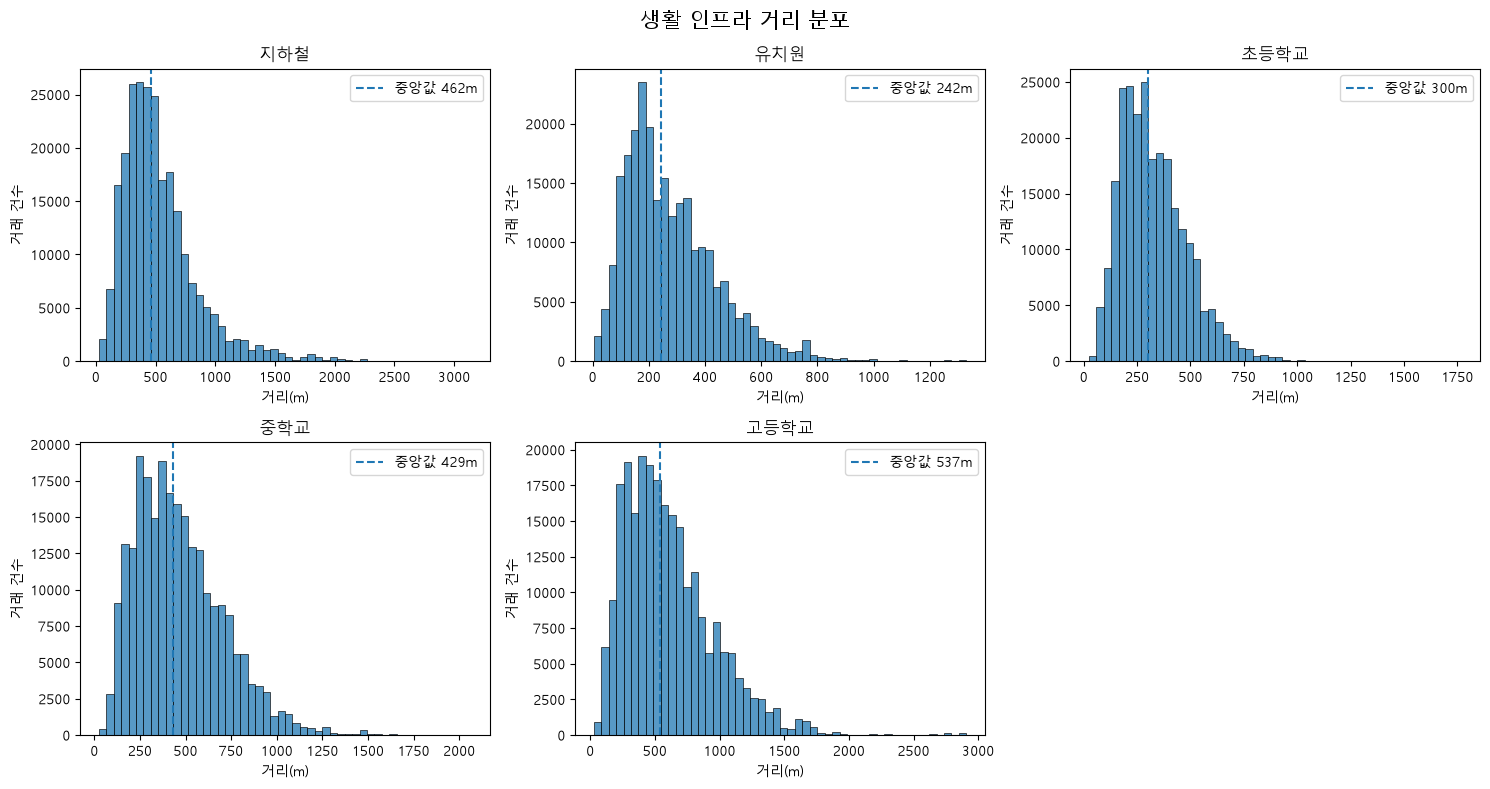

In [82]:
import seaborn as sns

distance_cols = [
    "역세권거리_m",
    "유치원거리_m",
    "초등학교거리_m",
    "중학교거리_m",
    "고등학교거리_m",
]

distance_labels = {
    "역세권거리_m": "지하철",
    "유치원거리_m": "유치원",
    "초등학교거리_m": "초등학교",
    "중학교거리_m": "중학교",
    "고등학교거리_m": "고등학교",
}

fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 8)
)

for ax, col in zip(axes.flat, distance_cols):
    values = df_fe[col].dropna()
    median_distance = values.median()

    sns.histplot(
        values,
        bins=50,
        ax=ax,
    )

    ax.axvline(
        median_distance,
        linestyle="--",
        linewidth=1.5,
        label=f"중앙값 {median_distance:,.0f}m",
    )

    ax.set_title(distance_labels[col])
    ax.set_xlabel("거리(m)")
    ax.set_ylabel("거래 건수")
    ax.legend()

axes.flat[-1].axis("off")

fig.suptitle(
    "생활 인프라 거리 분포",
    fontsize=15,
)

plt.tight_layout()
plt.show()


### 9-2. 거리 구간별 중위 평당가

거래금액은 전용면적의 영향을 크게 받기 때문에,
인프라 접근성과 가격의 관계는 **중위 평당가**로 비교합니다.

거리 구간은 해석이 쉬운 기준으로 `300m 이하`, `300~500m`, `500m~1km`,
`1~1.5km`, `1.5km 초과`로 나눕니다.


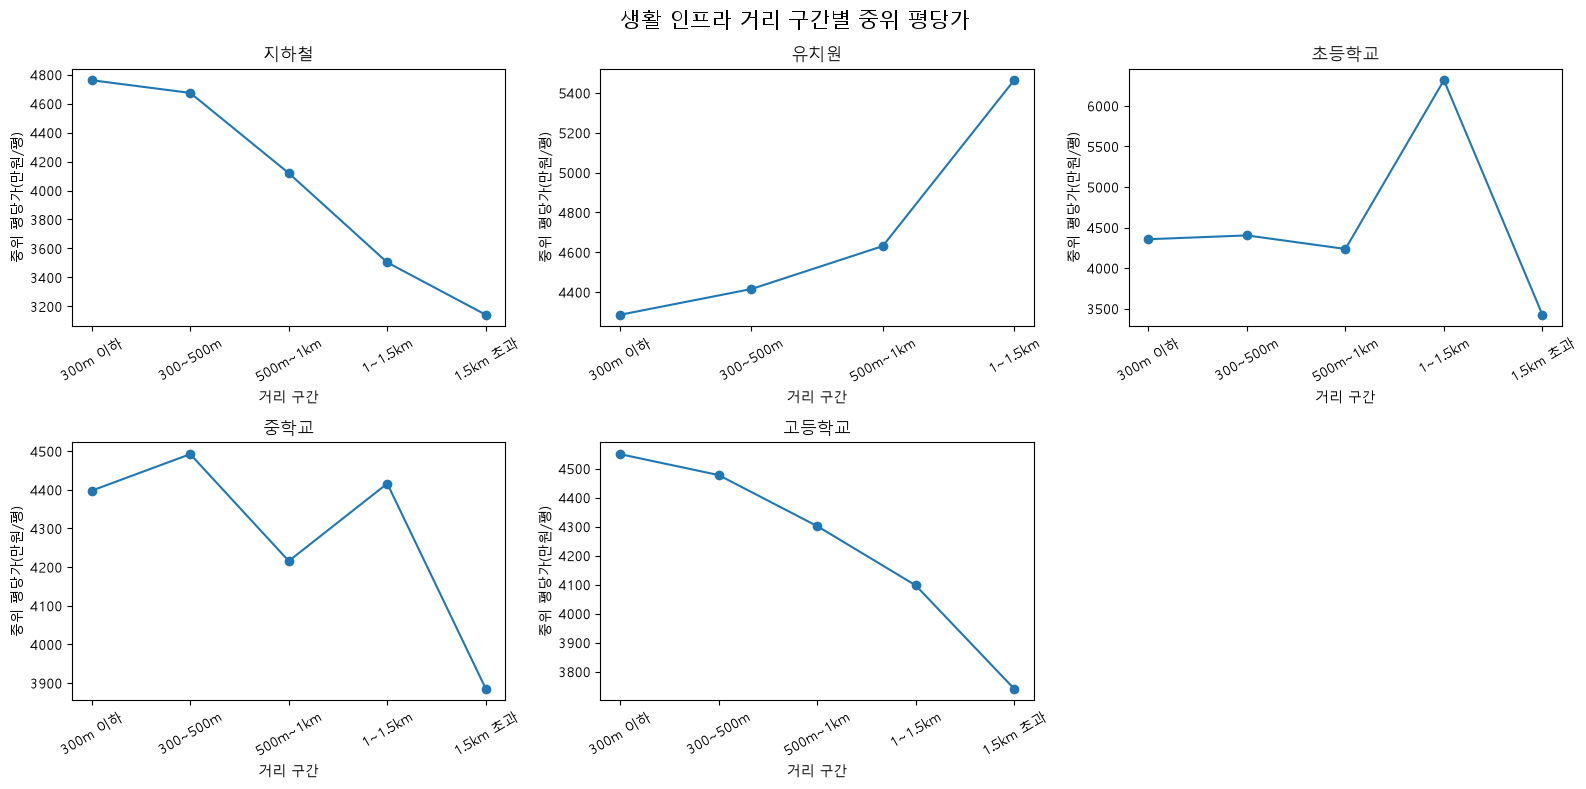

In [88]:
distance_bins = [
    0,
    300,
    500,
    1_000,
    1_500,
    np.inf,
]

distance_band_labels = [
    "300m 이하",
    "300~500m",
    "500m~1km",
    "1~1.5km",
    "1.5km 초과",
]


def summarize_distance_price(df, distance_col):
    plot_df = (
        df[[distance_col, "평당가"]]
        .dropna()
        .copy()
    )

    plot_df["거리구간"] = pd.cut(
        plot_df[distance_col],
        bins=distance_bins,
        labels=distance_band_labels,
        include_lowest=True,
    )

    return (
        plot_df.groupby(
            "거리구간",
            observed=True,
        )["평당가"]
        .median()
        .reindex(distance_band_labels)
    )


fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 8)
)

for ax, col in zip(axes.flat, distance_cols):
    summary = summarize_distance_price(
        df_fe,
        col,
    )

    ax.plot(
        summary.index,
        summary.values,
        marker="o",
    )

    ax.set_title(distance_labels[col])
    ax.set_xlabel("거리 구간")
    ax.set_ylabel("중위 평당가(만원/평)")
    ax.tick_params(
        axis="x",
        rotation=30,
    )

axes.flat[-1].axis("off")

fig.suptitle(
    "생활 인프라 거리 구간별 중위 평당가",
    fontsize=15,
)

plt.tight_layout()
plt.show()


### 9-3. 전용면적·연식과 가격 관계

전체 거래를 산점도로 그리면 점이 과도하게 겹치므로,
전용면적과 거래금액은 **hexbin 밀도 그래프**로 확인합니다.

연식은 기존에 만든 `연식_구분`을 사용해 그룹별 중위 평당가를 비교합니다.
시각화를 위해 거래금액과 전용면적의 상위 1%는 hexbin에서만 제외하며,
원본 데이터 자체는 변경하지 않습니다.


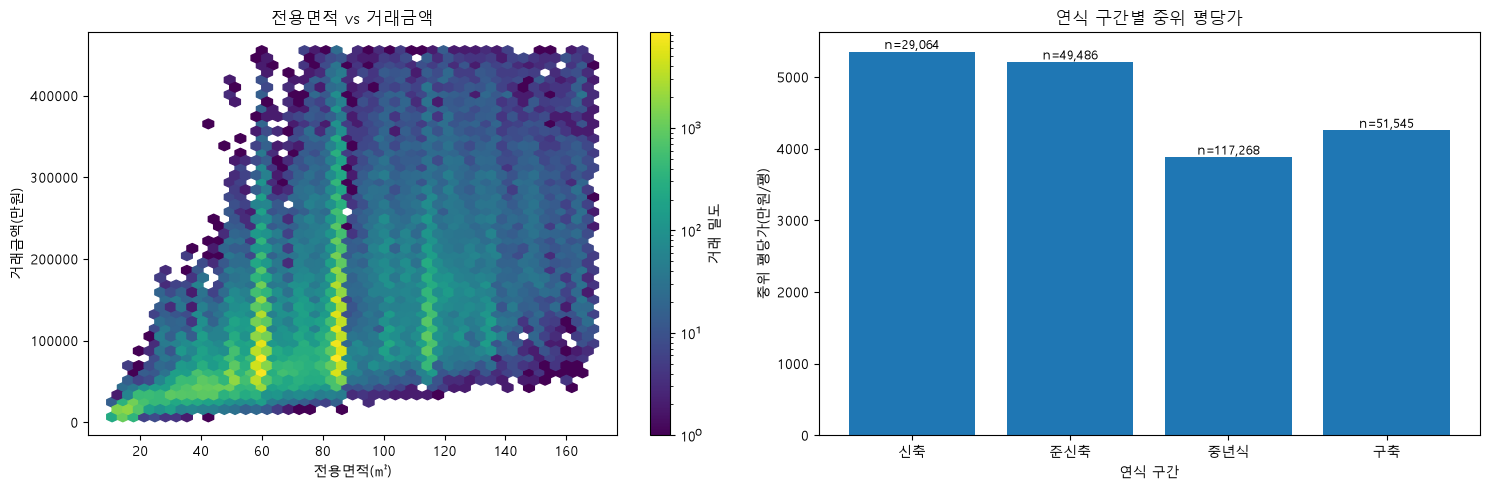

In [84]:
price_q99 = df_fe["거래금액"].quantile(0.99)
area_q99 = df_fe["전용면적"].quantile(0.99)

area_price_df = df_fe.loc[
    (df_fe["거래금액"] <= price_q99)
    & (df_fe["전용면적"] <= area_q99)
]

age_order = [
    "신축",
    "준신축",
    "중년식",
    "구축",
]

age_summary = (
    df_fe.dropna(
        subset=["연식_구분", "평당가"]
    )
    .groupby(
        "연식_구분",
        observed=True,
    )
    .agg(
        중위평당가=("평당가", "median"),
        거래건수=("평당가", "size"),
    )
    .reindex(age_order)
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5)
)

hexbin = axes[0].hexbin(
    area_price_df["전용면적"],
    area_price_df["거래금액"],
    gridsize=45,
    mincnt=1,
    bins="log",
)

axes[0].set_title("전용면적 vs 거래금액")
axes[0].set_xlabel("전용면적(㎡)")
axes[0].set_ylabel("거래금액(만원)")

fig.colorbar(
    hexbin,
    ax=axes[0],
    label="거래 밀도",
)

axes[1].bar(
    age_summary.index,
    age_summary["중위평당가"],
)

axes[1].set_title("연식 구간별 중위 평당가")
axes[1].set_xlabel("연식 구간")
axes[1].set_ylabel("중위 평당가(만원/평)")

for idx, row in enumerate(
    age_summary.itertuples()
):
    if pd.notna(row.중위평당가):
        axes[1].text(
            idx,
            row.중위평당가,
            f"n={row.거래건수:,.0f}",
            ha="center",
            va="bottom",
            fontsize=9,
        )

plt.tight_layout()
plt.show()


### 9-4. 자치구별 중위 평당가

서울 25개 자치구를 모두 포함해 중위 평당가를 비교합니다.
상·하위 일부 구만 보는 것보다 지역별 가격 수준의 전체 구조를 확인하기 쉽습니다.


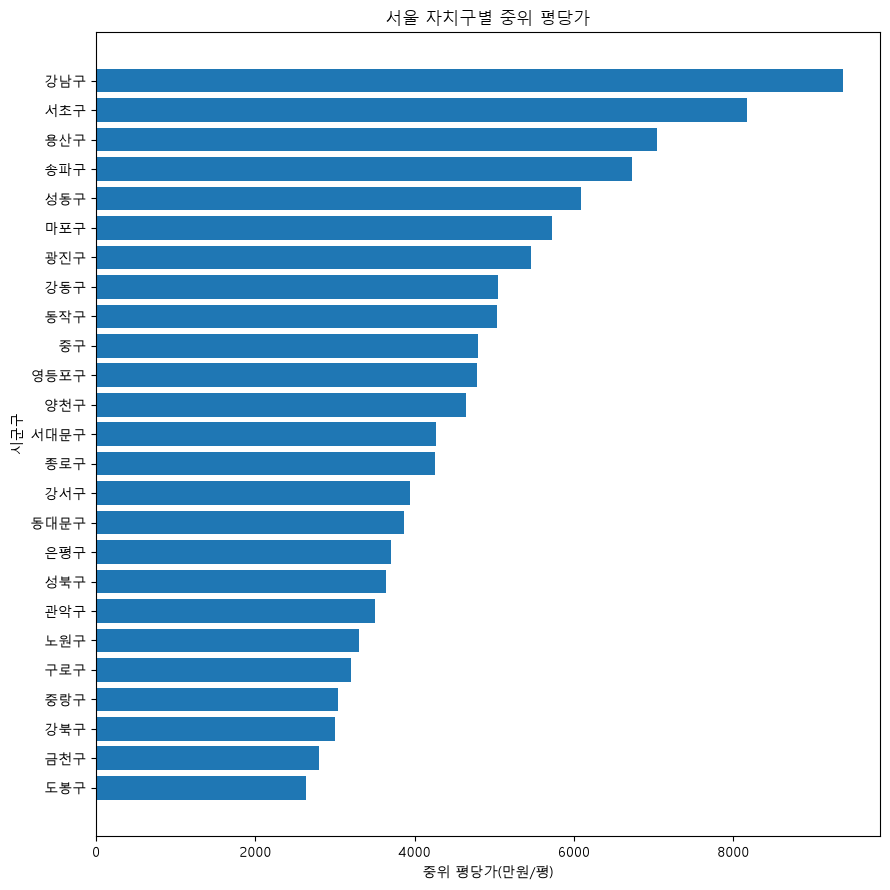

In [85]:
gu_price = (
    df_fe.groupby(
        "시군구명",
        observed=True,
    )
    .agg(
        중위평당가=("평당가", "median"),
        거래건수=("평당가", "size"),
    )
    .sort_values(
        "중위평당가",
        ascending=True,
    )
)

fig, ax = plt.subplots(
    figsize=(9, 9)
)

ax.barh(
    gu_price.index,
    gu_price["중위평당가"],
)

ax.set_title(
    "서울 자치구별 중위 평당가"
)
ax.set_xlabel(
    "중위 평당가(만원/평)"
)
ax.set_ylabel(
    "시군구"
)

plt.tight_layout()
plt.show()


### 9-5. 최종 수치 피처 간 상관관계

가격과의 단순 선형관계뿐 아니라 순위 기반 단조 관계도 확인할 수 있도록
**Spearman 상관계수**를 사용합니다.

`log_price`와 `평당가`는 분석용으로만 포함하며,
현재 거래가격에서 직접 만들어지므로 회귀 입력 피처로 사용하지 않습니다.


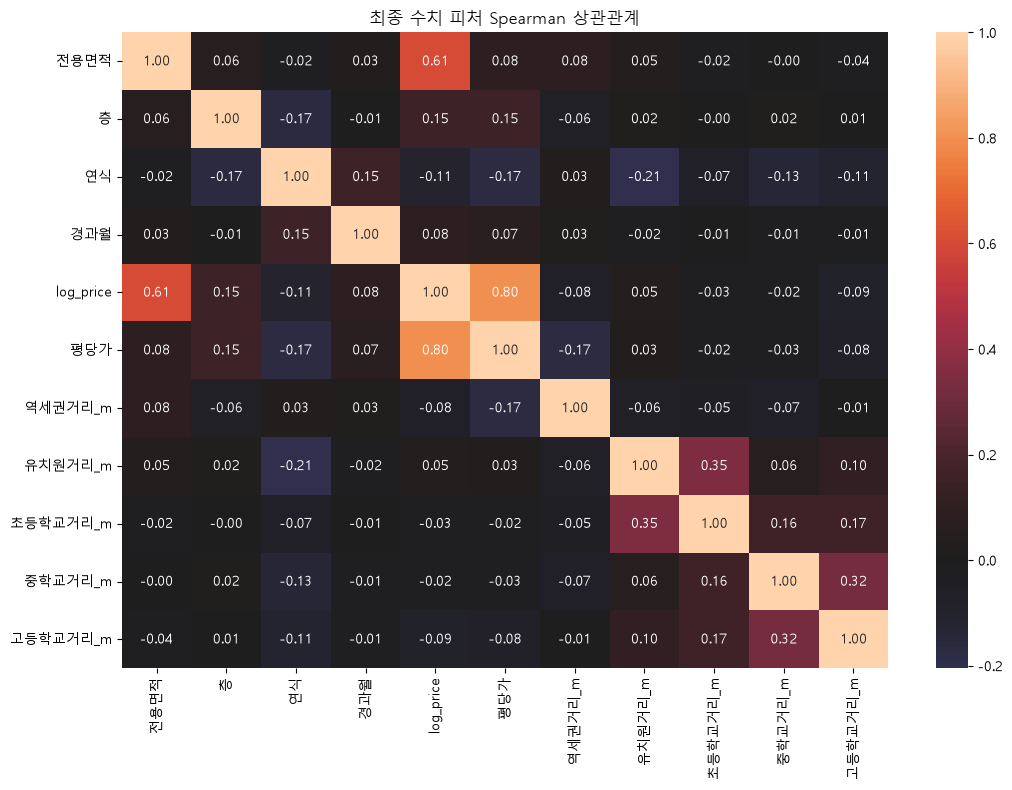

In [86]:
corr_cols = [
    "전용면적",
    "층",
    "연식",
    "경과월",
    "log_price",
    "평당가",
    "역세권거리_m",
    "유치원거리_m",
    "초등학교거리_m",
    "중학교거리_m",
    "고등학교거리_m",
]

corr = (
    df_fe[corr_cols]
    .corr(
        method="spearman"
    )
)

plt.figure(
    figsize=(11, 8)
)

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    center=0,
)

plt.title(
    "최종 수치 피처 Spearman 상관관계"
)

plt.tight_layout()
plt.show()


앞에서 이미 연도별·월별 가격과 거래량 추이를 확인했기 때문에
시간축 그래프는 여기서 중복해서 다시 그리지 않습니다.

이 시각화 섹션은 최종적으로 **가격 분포 자체보다 모델에 사용할 후보 피처의 관계를 점검하는 역할**에 집중합니다.


## 9-6. 피처 사용 가이드 — 회귀 누수 방지

### 회귀 입력으로 사용 가능한 후보
- 전용면적 / 층 / 연식
- 시군구 / 법정동 등 위치 범주
- 거래년도 / 거래월 / 분기 / 경과월 / 월_sin / 월_cos
- 역세권·학교 거리(현재 기준 입지 proxy라는 한계 문서화)
- `구_전월_중위가격`
- `구_과거3개월_중위가격`
- `구_과거6개월_중위가격`
- 과거 거래량 lag
- 가격을 사용하지 않고 Train으로 fit한 군집 피처

### 회귀 입력 금지
- `거래금액`
- `log_price`
- 현재 거래의 `평당가`
- 현재월 가격으로 계산한 지역 평균/중위가격
- `log_price`, `평당가`, 현재 거래금액이 포함된 군집 label

`04_regression`에서 실제 모델별 feature list를 만들 때 이 기준을 사용합니다.


## 10. 저장

5년 피처 데이터와 시장 국면 분석용 월별 지역 테이블을 저장합니다.

- `df_fe_5y.parquet`: 5년 버전 명시
- `df_fe.parquet`: 기존 하위 노트북 호환용 canonical
- `market_monthly_5y.parquet`: 시장 국면 군집/시계열 분석용

기존 `df_fe.parquet`가 있고 아직 5년 버전 파일이 없는 첫 실행이면
`df_fe_1year_backup.parquet`로 1회 백업합니다.


In [209]:
# ============================================================
# 최종 피처 데이터 저장
# ============================================================

df_fe.to_parquet(
    DF_FE_PATH,
    index=False,
)


# ============================================================
# 시장 월별 데이터 저장
# ============================================================

market_monthly = monthly_region_stats.merge(
    seoul_monthly_stats,
    on="거래월일자",
    how="left",
)

market_monthly.to_parquet(
    MARKET_MONTHLY_PATH,
    index=False,
)


# ============================================================
# 저장 결과 확인
# ============================================================

print(
    f"피처 데이터 저장 : {DF_FE_PATH}"
)
print(
    f"shape            : "
    f"{df_fe.shape[0]:,}행 × {df_fe.shape[1]}열"
)

print(
    f"\n시장 월별 데이터 : "
    f"{MARKET_MONTHLY_PATH}"
)
print(
    f"shape            : "
    f"{market_monthly.shape[0]:,}행 × "
    f"{market_monthly.shape[1]}열"
)

피처 데이터 저장 : c:\Users\uk\Apartment price\data\v2_5year_seoul\processed\df_fe.parquet
shape            : 247,385행 × 49열

시장 월별 데이터 : c:\Users\uk\Apartment price\data\v2_5year_seoul\processed\market_monthly.parquet
shape            : 1,500행 × 23열


실행 후 좌표 매핑 성공률과 실패 주소 수를 확인합니다.

5년 확장으로 과거 단지까지 포함되면서 실패 주소가 늘 수 있으므로,
실패가 특정 단지/옛 지번에 집중되는지 별도로 확인합니다.


## 다음 단계

1. `03_clustering_updated.ipynb`
   - 정적 생활인프라/역세권/재건축 군집 재실행
   - `market_monthly_5y.parquet`를 활용한 **시장 국면 군집** 추가 검토
2. `04_regression.ipynb`
   - 시간순 Train / Validation / Test
   - 기존 `지역평균가` 대신 **과거 월 lag 피처** 활용
   - 가격을 보지 않고 만든 군집 label / centroid distance / GMM probability 비교
3. `05_classification.ipynb`
   - 누수 없이 생성한 회귀 예측값/잔차를 기반으로 저평가 분류 설계

### 중요한 원칙
- 현재 거래금액으로 만든 `log_price`, `평당가`, 현재월 지역 통계 → 회귀 입력 금지
- 과거 월까지의 정보만 사용한 lag 피처 → 회귀 후보
- 최종 모델 검증은 Random Split이 아니라 **시간순 Holdout**


In [210]:
# 층을 포함해서, 진짜 "완전히 동일한 조건"인 경우만 확인
dup_count = df_eda.duplicated(
    subset=["단지일련번호", "계약년도", "계약월", "계약일", "전용면적", "층", "거래금액"]
).sum()
print(dup_count)

11688


In [211]:
dup_cols = [
    "단지일련번호",
    "계약년도",
    "계약월",
    "계약일",
    "전용면적",
    "층",
    "거래금액",
]

# 같은 거래 조건을 가진 모든 행
dup_mask = df_eda.duplicated(
    subset=dup_cols,
    keep=False,
)

dup_df = (
    df_eda.loc[dup_mask]
    .sort_values(dup_cols)
    .copy()
)

print("중복 의심 전체 행 수:", len(dup_df))

print(
    "중복 그룹 수:",
    dup_df.groupby(
        dup_cols,
        dropna=False,
    ).ngroups
)

# 모든 컬럼이 완전히 같은 행
print(
    "완전 동일 행 중복 수:",
    df_eda.duplicated().sum()
)

중복 의심 전체 행 수: 21353
중복 그룹 수: 9665
완전 동일 행 중복 수: 2461


In [212]:
dup_group_size = (
    dup_df.groupby(
        dup_cols,
        dropna=False,
    )
    .size()
)

display(
    dup_group_size
    .value_counts()
    .sort_index()
    .rename_axis("그룹당 행 수")
    .to_frame("그룹 수")
)

,그룹 수
그룹당 행 수,
2,8642
3,681
4,143
5,65
6,54
7,21
8,10
9,10
10,13


In [213]:
display(
    dup_df[
        [
            "단지일련번호",
            "단지명",
            "법정동",
            "계약년도",
            "계약월",
            "계약일",
            "전용면적",
            "층",
            "거래금액",
        ]
    ].head(30)
)

,단지일련번호,단지명,법정동,계약년도,계약월,계약일,전용면적,층,거래금액
626,11110-102,현대뜨레비앙,익선동,2023,10,19,48.540,4,43500
643,11110-102,현대뜨레비앙,익선동,2023,10,19,48.540,4,43500
388,11110-107,경희궁파크팰리스,내수동,2023,2,21,146.390,13,185000
394,11110-107,경희궁파크팰리스,내수동,2023,2,21,146.390,13,185000
534,11110-15,신문로맨션,신문로1가,2023,8,25,81.280,8,65000
536,11110-15,신문로맨션,신문로1가,2023,8,25,81.280,8,65000
1333,11110-152,롯데캐슬천지인,숭인동,2025,4,16,84.950,30,98000
1362,11110-152,롯데캐슬천지인,숭인동,2025,4,16,84.950,30,98000
1225,11110-16,운현신화타워,익선동,2025,2,1,78.230,15,70000
1240,11110-16,운현신화타워,익선동,2025,2,1,78.230,15,70000


In [214]:
dup_cols = [
    "단지일련번호",
    "계약년도",
    "계약월",
    "계약일",
    "전용면적",
    "층",
    "거래금액",
]

dup_df = (
    df_eda[
        df_eda.duplicated(
            subset=dup_cols,
            keep=False,
        )
    ]
    .copy()
)

check_cols = [
    col
    for col in df_eda.columns
    if col not in dup_cols
]

variation = (
    dup_df.groupby(
        dup_cols,
        dropna=False,
    )[check_cols]
    .nunique(dropna=False)
)

varying_cols = (
    (variation > 1)
    .sum()
    .sort_values(ascending=False)
)

display(
    varying_cols[
        varying_cols > 0
    ].to_frame(
        "값이 달랐던 중복 그룹 수"
    )
)

,값이 달랐던 중복 그룹 수
해제사유발생일,8410
해제여부,8345
등기일자,7784
아파트동명,7336
중개사소재지,349
거래유형,47
매도자,11
매수자,10
도로명일련번호코드,3
도로명,3


In [215]:
exact_dup_mask = df_eda.duplicated(
    keep=False,
)

exact_dup_df = df_eda[
    exact_dup_mask
].copy()

exact_group_size = (
    exact_dup_df
    .groupby(
        list(df_eda.columns),
        dropna=False,
    )
    .size()
)

display(
    exact_group_size
    .value_counts()
    .sort_index()
    .rename_axis("완전 동일 반복 횟수")
    .to_frame("그룹 수")
)

,그룹 수
완전 동일 반복 횟수,
2,917
3,174
4,86
5,42
6,35
7,27
8,13
9,14
10,10


In [217]:
# ============================================================
# 해제 거래 확인
# ============================================================

display(
    df_eda["해제여부"]
    .value_counts(dropna=False)
    .to_frame("건수")
)

print(
    "해제사유발생일 존재:",
    df_eda["해제사유발생일"]
    .notna()
    .sum()
)

,건수
해제여부,
<NA>,234302
O,13083


해제사유발생일 존재: 13083
